
# Late Delivery Prediction for an E-commerce Marketplace

## 1. Business Problem

Late deliveries negatively affect customer satisfaction
and business performance in e-commerce marketplaces.

The goal of this project is to develop a Machine Learning
classification model that predicts whether an order
will be delivered later than its estimated delivery date.

## Business Objective
- Identify high-risk orders.
- Help logistics teams prioritize deliveries.
- Monitor seller delivery performance.

## Dataset
Brazilian E-Commerce Public Dataset by Olist.


In [1]:

# Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import os
import pandas as pd
import numpy as np

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Check available datasets
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            print(os.path.join(dirname, filename))


/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_customers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_geolocation_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_items_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_payments_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_order_reviews_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_orders_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_products_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/olist_sellers_dataset.csv
/kaggle/input/datasets/olistbr/brazilian-ecommerce/product_category_name_translation.csv


In [3]:

import glob

# Find all CSV files
csv_files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

# Load all datasets into a dictionary
data = {}

for file in csv_files:
    table_name = os.path.basename(file).replace('.csv', '')
    data[table_name] = pd.read_csv(file)

print(f"Total tables loaded: {len(data)}")


Total tables loaded: 9


In [4]:

# Dataset overview

overview = pd.DataFrame({
    'Table': [name for name in data.keys()],
    'Rows': [df.shape[0] for df in data.values()],
    'Columns': [df.shape[1] for df in data.values()],
    'Duplicates': [df.duplicated().sum() for df in data.values()]
})

overview


,Table,Rows,Columns,Duplicates
0,olist_customers_dataset,99441,5,0
1,olist_geolocation_dataset,1000163,5,261831
2,olist_order_items_dataset,112650,7,0
3,olist_order_payments_dataset,103886,5,0
4,olist_order_reviews_dataset,99224,7,0
5,olist_orders_dataset,99441,8,0
6,olist_products_dataset,32951,9,0
7,olist_sellers_dataset,3095,4,0
8,product_category_name_translation,71,2,0


In [5]:

for name, df in data.items():
    print(f"\n{'='*60}")
    print(f"TABLE: {name}")
    print(f"{'='*60}")

    print("Columns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)



TABLE: olist_customers_dataset
Columns:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Data Types:
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object

TABLE: olist_geolocation_dataset
Columns:
['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Data Types:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object

TABLE: olist_order_items_dataset
Columns:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Data Types:
order_id                object
order_item_id            int64
product_id              object
seller_id               o

In [6]:

# Missing Values Analysis

missing_report = []

for name, df in data.items():
    for col in df.columns:
        missing_count = df[col].isnull().sum()

        missing_report.append({
            'Table': name,
            'Column': col,
            'Missing Values': missing_count,
            'Missing %': round(
                (missing_count / len(df)) * 100, 2
            )
        })

missing_df = pd.DataFrame(missing_report)

missing_df = missing_df[
    missing_df['Missing Values'] > 0
].sort_values(
    by='Missing %',
    ascending=False
)

missing_df


,Table,Column,Missing Values,Missing %
25,olist_order_reviews_dataset,review_comment_title,87656,88.34
26,olist_order_reviews_dataset,review_comment_message,58247,58.70
35,olist_orders_dataset,order_delivered_customer_date,2965,2.98
39,olist_products_dataset,product_name_lenght,610,1.85
38,olist_products_dataset,product_category_name,610,1.85
40,olist_products_dataset,product_description_lenght,610,1.85
41,olist_products_dataset,product_photos_qty,610,1.85
34,olist_orders_dataset,order_delivered_carrier_date,1783,1.79
33,olist_orders_dataset,order_approved_at,160,0.16
42,olist_products_dataset,product_weight_g,2,0.01


In [7]:

# Check key uniqueness

key_checks = {
    'olist_orders_dataset': 'order_id',
    'olist_customers_dataset': 'customer_id',
    'olist_sellers_dataset': 'seller_id',
    'olist_products_dataset': 'product_id'
}

for table, key in key_checks.items():

    df = data[table]

    print(f"\nTable: {table}")
    print(f"Total Rows: {len(df)}")
    print(f"Unique {key}: {df[key].nunique()}")
    print(f"Duplicate Keys: {df[key].duplicated().sum()}")



Table: olist_orders_dataset
Total Rows: 99441
Unique order_id: 99441
Duplicate Keys: 0

Table: olist_customers_dataset
Total Rows: 99441
Unique customer_id: 99441
Duplicate Keys: 0

Table: olist_sellers_dataset
Total Rows: 3095
Unique seller_id: 3095
Duplicate Keys: 0

Table: olist_products_dataset
Total Rows: 32951
Unique product_id: 32951
Duplicate Keys: 0


In [8]:

orders = data['olist_orders_dataset']

print("Shape:", orders.shape)

display(orders.head())

print("\nOrder Status Distribution:")
display(orders['order_status'].value_counts())

print("\nOrder Timestamp Information:")
display(orders.describe(include='all').T)


Shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00



Order Status Distribution:


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


Order Timestamp Information:


,count,unique,top,freq
order_id,99441,99441,66dea50a8b16d9b4dee7af250b4be1a5,1
customer_id,99441,99441,edb027a75a1449115f6b43211ae02a24,1
order_status,99441,8,delivered,96478
order_purchase_timestamp,99441,98875,2018-08-02 12:06:07,3
order_approved_at,99281,90733,2018-02-27 04:31:10,9
order_delivered_carrier_date,97658,81018,2018-05-09 15:48:00,47
order_delivered_customer_date,96476,95664,2018-05-14 20:02:44,3
order_estimated_delivery_date,99441,459,2017-12-20 00:00:00,522


In [9]:

orders = data['olist_orders_dataset'].copy()

date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

orders[date_columns].dtypes


order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [10]:

# Compare order status with delivery date availability

delivery_check = pd.crosstab(
    orders['order_status'],
    orders['order_delivered_customer_date'].isna(),
    margins=True
)

delivery_check.columns = [
    'Delivery Date Available',
    'Delivery Date Missing',
    'Total'
]

delivery_check


,Delivery Date Available,Delivery Date Missing,Total
order_status,,,
approved,0,2,2
canceled,6,619,625
created,0,5,5
delivered,96470,8,96478
invoiced,0,314,314
processing,0,301,301
shipped,0,1107,1107
unavailable,0,609,609
All,96476,2965,99441


In [11]:

# Select eligible delivered orders

delivered_orders = orders[
    (orders['order_status'] == 'delivered') &
    (orders['order_delivered_customer_date'].notna()) &
    (orders['order_estimated_delivery_date'].notna())
].copy()

# Create target variable
delivered_orders['is_late'] = (
    delivered_orders['order_delivered_customer_date'] >
    delivered_orders['order_estimated_delivery_date']
).astype(int)

print("Eligible Orders:", len(delivered_orders))

print("\nTarget Distribution:")
display(delivered_orders['is_late'].value_counts())

print("\nTarget Percentage:")
display(
    delivered_orders['is_late']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Eligible Orders: 96470

Target Distribution:


is_late
0    88644
1     7826
Name: count, dtype: int64


Target Percentage:


is_late
0    91.89
1     8.11
Name: proportion, dtype: float64

In [12]:

# Calculate delivery delay in days

delivered_orders['delivery_delay_days'] = (
    delivered_orders['order_delivered_customer_date'] -
    delivered_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

print("Average Delivery Delay (days):",
      round(delivered_orders['delivery_delay_days'].mean(), 2))

print("\nDelivery Delay Statistics:")
display(delivered_orders['delivery_delay_days'].describe())


Average Delivery Delay (days): -11.18

Delivery Delay Statistics:


count    96470.000000
mean       -11.178126
std         10.184354
min       -146.016123
25%        -16.244065
50%        -11.948102
75%         -6.389815
max        188.975081
Name: delivery_delay_days, dtype: float64

In [13]:

# Delivery performance by target class

delay_analysis = delivered_orders.groupby('is_late')[
    'delivery_delay_days'
].agg([
    'count',
    'mean',
    'median',
    'min',
    'max',
    'std'
]).round(2)

delay_analysis.index = ['On Time / Early', 'Late']

display(delay_analysis)


,count,mean,median,min,max,std
On Time / Early,88644,-13.01,-12.32,-146.02,-0.00,7.38
Late,7826,9.55,5.81,0.00,188.98,13.95


In [14]:

# Inspect the 10 most delayed orders

display(
    delivered_orders.nlargest(
        10, 'delivery_delay_days'
    )[
        [
            'order_id',
            'order_purchase_timestamp',
            'order_delivered_customer_date',
            'order_estimated_delivery_date',
            'delivery_delay_days',
            'is_late'
        ]
    ]
)


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,is_late
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,188.975081,1
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,181.608785,1
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,175.869109,1
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,167.708414,1
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,166.583380,1
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,165.633912,1
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,162.718345,1
40847,d24e8541128cea179a11a65176e0a96f,2017-06-12 13:14:11,2017-12-04 18:36:29,2017-06-26,161.775336,1
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,161.609965,1
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,159.609931,1


In [15]:

# Check chronological inconsistencies

chronology_checks = {
    'Approval before Purchase':
        orders['order_approved_at'] <
        orders['order_purchase_timestamp'],

    'Carrier before Purchase':
        orders['order_delivered_carrier_date'] <
        orders['order_purchase_timestamp'],

    'Delivery before Purchase':
        orders['order_delivered_customer_date'] <
        orders['order_purchase_timestamp'],

    'Delivery before Carrier':
        orders['order_delivered_customer_date'] <
        orders['order_delivered_carrier_date']
}

for check, condition in chronology_checks.items():
    print(f'{check}: {condition.sum()}')


Approval before Purchase: 0
Carrier before Purchase: 166
Delivery before Purchase: 0
Delivery before Carrier: 23


In [16]:

# Investigate unusual delivery date

september_orders = delivered_orders[
    delivered_orders['order_delivered_customer_date'].dt.date ==
    pd.Timestamp('2018-09-19').date()
].copy()

print("Orders delivered on 2018-09-19:", len(september_orders))

print("\nLate vs On-Time:")
display(september_orders['is_late'].value_counts())

print("\nEstimated Delivery Dates:")
display(
    september_orders['order_estimated_delivery_date']
    .value_counts()
    .head(10)
)

display(
    september_orders[
        [
            'order_id',
            'order_purchase_timestamp',
            'order_delivered_carrier_date',
            'order_delivered_customer_date',
            'order_estimated_delivery_date',
            'delivery_delay_days'
        ]
    ].head(15)
)


Orders delivered on 2018-09-19: 3

Late vs On-Time:


is_late
1    3
Name: count, dtype: int64


Estimated Delivery Dates:


order_estimated_delivery_date
2018-07-31    1
2018-03-15    1
2018-08-17    1
Name: count, dtype: int64

,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days
44573,ae213a9f84c777fb7a31e8c0f09fd30c,2018-07-03 22:13:48,2018-07-04 16:17:00,2018-09-19 15:46:39,2018-07-31,50.657396
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,188.975081
96277,4505acb3759da6b9c7d79a80d29ab3bb,2018-08-06 14:32:27,2018-09-11 19:48:28,2018-09-19 16:44:44,2018-08-17,33.697731


In [17]:

carrier_anomalies = orders[
    orders['order_delivered_carrier_date'] <
    orders['order_purchase_timestamp']
].copy()

print("Total anomalies:", len(carrier_anomalies))

display(
    carrier_anomalies[
        [
            'order_id',
            'order_purchase_timestamp',
            'order_approved_at',
            'order_delivered_carrier_date',
            'order_delivered_customer_date',
            'order_estimated_delivery_date',
            'order_status'
        ]
    ].head(20)
)


Total anomalies: 166


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_status
615,b9afddbdcfadc9a87b41a83271c3e888,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00,2018-08-24 14:58:37,2018-09-04,delivered
1111,ad133696906f6a78826daa0911b7daec,2018-06-15 15:41:22,2018-06-15 16:19:23,2018-06-15 14:52:00,2018-06-22 18:09:37,2018-07-18,delivered
1329,74e033208dc13a7b8127eb8e73d09b76,2018-05-02 10:48:44,2018-05-02 11:13:45,2018-05-02 09:49:00,2018-05-07 23:06:36,2018-05-29,delivered
1372,a6b58794fd2ba533359a76c08df576e3,2018-05-14 15:18:23,2018-05-14 15:33:35,2018-05-14 13:46:00,2018-05-19 19:33:32,2018-06-08,delivered
1864,5792e0b1c8c8a2bf53af468c9a422c88,2018-07-26 13:25:14,2018-07-26 13:35:14,2018-07-26 12:42:00,2018-07-30 14:45:02,2018-08-09,delivered
2760,c3eb293fd154223498b6551a728203e8,2018-07-19 14:06:04,2018-07-19 14:22:51,2018-07-19 13:49:00,2018-07-24 19:35:36,2018-08-06,delivered
3473,b0c2a7d04b165525254254a728c50a4e,2018-06-07 13:28:30,2018-06-07 13:57:22,2018-06-07 13:22:00,2018-06-21 17:36:43,2018-07-04,delivered
3661,2033a4586b5bec3229ebc1675a8ae092,2018-06-12 10:10:25,2018-06-12 10:39:59,2018-06-12 10:09:00,2018-06-19 14:08:27,2018-07-19,delivered
4114,08adcddad19d3acf37d1fa01cb9ded1e,2018-06-27 11:16:44,2018-06-27 11:30:56,2018-06-27 10:57:00,2018-06-29 17:39:53,2018-07-18,delivered
4159,dee6298ce7d1fb2645141ef9972157aa,2018-04-30 14:06:12,2018-04-30 14:15:24,2018-04-30 12:59:00,NaT,2018-05-28,shipped


In [18]:

delivery_anomalies = orders[
    orders['order_delivered_customer_date'] <
    orders['order_delivered_carrier_date']
].copy()

print("Total anomalies:", len(delivery_anomalies))

display(
    delivery_anomalies[
        [
            'order_id',
            'order_purchase_timestamp',
            'order_delivered_carrier_date',
            'order_delivered_customer_date',
            'order_estimated_delivery_date'
        ]
    ]
)


Total anomalies: 23


,order_id,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
6437,a1abeb653a4d4cd1e142ccb8c82cd069,2017-07-20 11:20:52,2017-07-28 16:57:58,2017-07-25 19:32:56,2017-08-14
9553,383aa8b2724fe452d9ccd9934a8c628b,2017-07-02 20:58:43,2017-07-07 17:22:41,2017-07-06 14:27:51,2017-07-21
13487,cb1134f9010d242e9515ad1c78ec0c39,2017-07-16 12:35:34,2017-07-20 19:22:02,2017-07-19 14:13:28,2017-08-08
14474,dceb62e8fa94b46006c9554fed743df0,2017-07-20 20:58:05,2017-08-01 18:23:30,2017-07-26 18:09:10,2017-08-11
19268,5f9d46795c3126674e52becb3a1a517f,2017-07-18 11:48:20,2017-07-20 23:03:42,2017-07-20 18:52:41,2017-07-31
21338,8c78d01de3a9009e23d6877a7cc9be20,2016-10-08 15:36:50,2016-10-26 11:41:53,2016-10-25 17:51:46,2016-11-30
22520,b27af682321527a6349f1761eb3f360c,2017-06-14 20:17:04,2017-06-27 14:51:54,2017-06-26 15:45:35,2017-07-14
25393,1cc3ae63caffff2d6c3ee3e78e074acf,2017-08-07 21:35:22,2017-08-10 18:28:56,2017-08-10 18:05:38,2017-08-25
25646,e37f11cae9985ca58f0b56f268720537,2017-07-26 11:46:34,2017-08-01 18:17:47,2017-07-31 17:49:56,2017-08-24
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,2017-07-30 19:32:23,2017-08-09 18:18:43,2017-08-01 21:13:01,2017-08-18


In [19]:

# 1. How many days is the carrier date before purchase?
carrier_anomalies['carrier_before_purchase_days'] = (
    carrier_anomalies['order_purchase_timestamp'] -
    carrier_anomalies['order_delivered_carrier_date']
).dt.total_seconds() / 86400

print("Carrier anomaly gap (days):")
display(carrier_anomalies['carrier_before_purchase_days'].describe())

# 2. How many days is delivery before carrier?
delivery_anomalies['delivery_before_carrier_hours'] = (
    delivery_anomalies['order_delivered_carrier_date'] -
    delivery_anomalies['order_delivered_customer_date']
).dt.total_seconds() / 3600

print("Delivery anomaly gap (hours):")
display(delivery_anomalies['delivery_before_carrier_hours'].describe())

# 3. Check whether the 23 delivery anomalies affect our target
delivery_anomaly_ids = delivery_anomalies['order_id']

affected = delivered_orders[
    delivered_orders['order_id'].isin(delivery_anomaly_ids)
]

print("Delivery anomalies included in target dataset:", len(affected))
print("\nTheir target distribution:")
display(affected['is_late'].value_counts())


Carrier anomaly gap (days):


count    166.000000
mean       1.084978
std       13.288494
min        0.000278
25%        0.009769
50%        0.024994
75%        0.042396
max      171.212419
Name: carrier_before_purchase_days, dtype: float64

Delivery anomaly gap (hours):


count     23.000000
mean      78.455133
std       89.308070
min        0.388333
25%       23.338333
50%       39.864444
75%      128.759028
max      386.308056
Name: delivery_before_carrier_hours, dtype: float64

Delivery anomalies included in target dataset: 23

Their target distribution:


is_late
0    23
Name: count, dtype: int64

In [20]:

# Keep original data unchanged
delivery_anomaly_ids = delivery_anomalies['order_id']

model_orders = delivered_orders[
    ~delivered_orders['order_id'].isin(delivery_anomaly_ids)
].copy()

print("Original target dataset:", len(delivered_orders))
print("Excluded delivery anomalies:", len(affected))
print("Clean modeling dataset:", len(model_orders))

print("\nTarget distribution:")
display(model_orders['is_late'].value_counts())

print("\nTarget percentage:")
display(
    model_orders['is_late']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Original target dataset: 96470
Excluded delivery anomalies: 23
Clean modeling dataset: 96447

Target distribution:


is_late
0    88621
1     7826
Name: count, dtype: int64


Target percentage:


is_late
0    91.89
1     8.11
Name: proportion, dtype: float64

In [21]:

# Load tables from the data dictionary
orders_raw = data['olist_orders_dataset']
items = data['olist_order_items_dataset']
customers = data['olist_customers_dataset']
products = data['olist_products_dataset']
sellers = data['olist_sellers_dataset']
payments = data['olist_order_payments_dataset']
reviews = data['olist_order_reviews_dataset']

# Check foreign key coverage
relationships = [
    (items, 'order_id', orders_raw, 'order_id', 'Items -> Orders'),
    (items, 'product_id', products, 'product_id', 'Items -> Products'),
    (items, 'seller_id', sellers, 'seller_id', 'Items -> Sellers'),
    (orders_raw, 'customer_id', customers, 'customer_id', 'Orders -> Customers'),
    (payments, 'order_id', orders_raw, 'order_id', 'Payments -> Orders'),
    (reviews, 'order_id', orders_raw, 'order_id', 'Reviews -> Orders')
]

for child, child_key, parent, parent_key, name in relationships:
    unmatched = (~child[child_key].isin(parent[parent_key])).sum()

    print(f"{name}")
    print(f"  Total records: {len(child):,}")
    print(f"  Unmatched keys: {unmatched:,}")
    print("-" * 40)

# Check whether order-level tables contain duplicate order IDs
print("\nDuplicate order IDs:")
print("Items:", items['order_id'].duplicated().sum())
print("Payments:", payments['order_id'].duplicated().sum())
print("Reviews:", reviews['order_id'].duplicated().sum())


Items -> Orders
  Total records: 112,650
  Unmatched keys: 0
----------------------------------------
Items -> Products
  Total records: 112,650
  Unmatched keys: 0
----------------------------------------
Items -> Sellers
  Total records: 112,650
  Unmatched keys: 0
----------------------------------------
Orders -> Customers
  Total records: 99,441
  Unmatched keys: 0
----------------------------------------
Payments -> Orders
  Total records: 103,886
  Unmatched keys: 0
----------------------------------------
Reviews -> Orders
  Total records: 99,224
  Unmatched keys: 0
----------------------------------------

Duplicate order IDs:
Items: 13984
Payments: 4446
Reviews: 551


In [22]:

# Load category translation table
category_translation = data['product_category_name_translation']

# Add product information to each order item
items_enriched = items.merge(
    products,
    on='product_id',
    how='left'
)

# Translate product categories into English
items_enriched = items_enriched.merge(
    category_translation,
    on='product_category_name',
    how='left'
)

# Use English category when available
items_enriched['category'] = (
    items_enriched['product_category_name_english']
    .fillna('unknown')
)

print("Enriched items shape:", items_enriched.shape)

display(
    items_enriched[
        ['order_id', 'product_id', 'seller_id',
         'price', 'freight_value', 'category']
    ].head()
)


Enriched items shape: (112650, 17)


,order_id,product_id,seller_id,price,freight_value,category
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,17.87,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,18.14,garden_tools


In [23]:

# Aggregate numerical and count features
order_items_features = (
    items_enriched.groupby('order_id')
    .agg(
        item_count=('order_item_id', 'count'),
        unique_sellers=('seller_id', 'nunique'),
        unique_products=('product_id', 'nunique'),

        total_price=('price', 'sum'),
        total_freight=('freight_value', 'sum'),

        avg_item_price=('price', 'mean'),
        max_item_price=('price', 'max'),

        avg_freight=('freight_value', 'mean'),

        # total_weight_g=('product_weight_g', 'sum'),
       total_weight_g=(
          'product_weight_g',
          lambda x: x.sum(min_count=1) 
           ),
        avg_weight_g=('product_weight_g', 'mean'),

        avg_product_length=('product_length_cm', 'mean'),
        avg_product_height=('product_height_cm', 'mean'),
        avg_product_width=('product_width_cm', 'mean')
    )
    .reset_index()
)

# Get the most frequent product category in each order
main_category = (
    items_enriched.groupby('order_id')['category']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else 'unknown')
    .reset_index(name='main_category')
)

# Merge category feature
order_items_features = order_items_features.merge(
    main_category,
    on='order_id',
    how='left'
)

print("Order-level features shape:", order_items_features.shape)
display(order_items_features.head())


Order-level features shape: (98666, 15)


,order_id,item_count,unique_sellers,unique_products,total_price,total_freight,avg_item_price,max_item_price,avg_freight,total_weight_g,avg_weight_g,avg_product_length,avg_product_height,avg_product_width,main_category
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,1,58.90,13.29,58.90,58.90,13.29,650.0,650.0,28.0,9.0,14.0,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,1,239.90,19.93,239.90,239.90,19.93,30000.0,30000.0,50.0,30.0,40.0,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,1,199.00,17.87,199.00,199.00,17.87,3050.0,3050.0,33.0,13.0,33.0,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,1,1,12.99,12.79,12.99,12.99,12.79,200.0,200.0,16.0,10.0,15.0,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,1,199.90,18.14,199.90,199.90,18.14,3750.0,3750.0,35.0,40.0,30.0,garden_tools


In [24]:

# 1. Check target orders without item records
target_order_ids = set(model_orders['order_id'])
item_order_ids = set(order_items_features['order_id'])

missing_item_orders = target_order_ids - item_order_ids

print("Target orders:", len(target_order_ids))
print("Target orders without items:", len(missing_item_orders))

# 2. Check missing values in enriched items
print("\nMissing values in enriched items:")
display(
    items_enriched.isna().sum()
    .sort_values(ascending=False)
    .head(10)
)

# 3. Check missing values in order-level features
print("\nMissing values in order-level features:")
display(
    order_items_features.isna().sum()
    .sort_values(ascending=False)
)

# 4. Check unknown categories
print("\nUnknown categories:")
print(
    (items_enriched['category'] == 'unknown').sum()
)



Target orders: 96447
Target orders without items: 0

Missing values in enriched items:


product_category_name_english    1627
product_photos_qty               1603
product_category_name            1603
product_description_lenght       1603
product_name_lenght              1603
product_width_cm                   18
product_weight_g                   18
product_height_cm                  18
product_length_cm                  18
order_id                            0
dtype: int64


Missing values in order-level features:


avg_product_height    16
total_weight_g        16
avg_product_width     16
avg_product_length    16
avg_weight_g          16
item_count             0
order_id               0
avg_item_price         0
total_freight          0
total_price            0
unique_products        0
unique_sellers         0
avg_freight            0
max_item_price         0
main_category          0
dtype: int64


Unknown categories:
1627


In [25]:

# Count sellers per order
seller_count_per_order = (
    items_enriched.groupby('order_id')['seller_id']
    .nunique()
)

# Check orders with multiple sellers
multi_seller_orders = seller_count_per_order[
    seller_count_per_order > 1
]

print("Total orders with items:", len(seller_count_per_order))
print("Orders with multiple sellers:", len(multi_seller_orders))
print(
    "Percentage:",
    round(len(multi_seller_orders) / len(seller_count_per_order) * 100, 2),
    "%"
)

print("\nSeller count distribution:")
display(seller_count_per_order.value_counts().sort_index())


Total orders with items: 98666
Orders with multiple sellers: 1278
Percentage: 1.3 %

Seller count distribution:


seller_id
1    97388
2     1219
3       54
4        3
5        2
Name: count, dtype: int64

In [26]:

customer_features = customers[
    [
        'customer_id',
        'customer_zip_code_prefix',
        'customer_city',
        'customer_state'
    ]
].copy()

print("Customer features shape:", customer_features.shape)
display(customer_features.head())


Customer features shape: (99441, 4)


,customer_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,13056,campinas,SP


In [27]:

# Prepare seller information
seller_features = sellers[
    [
        'seller_id',
        'seller_zip_code_prefix',
        'seller_city',
        'seller_state'
    ]
].copy()

# Attach seller information to order items
items_with_sellers = items_enriched.merge(
    seller_features,
    on='seller_id',
    how='left'
)

# Count items for each seller within each order
seller_item_counts = (
    items_with_sellers
    .groupby(['order_id', 'seller_id'])
    .size()
    .reset_index(name='seller_item_count')
)

# Select the primary seller (most items in the order)
primary_sellers = (
    seller_item_counts
    .sort_values(
        ['order_id', 'seller_item_count', 'seller_id'],
        ascending=[True, False, True]
    )
    .drop_duplicates('order_id')
)

# Attach the primary seller's location
order_seller_features = primary_sellers.merge(
    seller_features,
    on='seller_id',
    how='left'
)

order_seller_features = order_seller_features[
    [
        'order_id',
        'seller_state',
        'seller_city',
        'seller_zip_code_prefix'
    ]
]

print("Seller features shape:", order_seller_features.shape)
display(order_seller_features.head())


Seller features shape: (98666, 4)


,order_id,seller_state,seller_city,seller_zip_code_prefix
0,00010242fe8c5a6d1ba2dd792cb16214,SP,volta redonda,27277
1,00018f77f2f0320c557190d7a144bdd3,SP,sao paulo,3471
2,000229ec398224ef6ca0657da4fc703e,MG,borda da mata,37564
3,00024acbcdf0a6daa1e931b038114c75,SP,franca,14403
4,00042b26cf59d7ce69dfabb4e55b4fd9,PR,loanda,87900


In [28]:

# Keep only purchase-time information and target
master_df = model_orders[
    [
        'order_id',
        'customer_id',
        'order_purchase_timestamp',
        'is_late'
    ]
].copy()

# Merge product and order-level features
master_df = master_df.merge(
    order_items_features,
    on='order_id',
    how='left',
    validate='one_to_one'
)

# Merge customer information
master_df = master_df.merge(
    customer_features,
    on='customer_id',
    how='left',
    validate='many_to_one'
)

# Merge primary seller information
master_df = master_df.merge(
    order_seller_features,
    on='order_id',
    how='left',
    validate='one_to_one'
)

print("Master Dataset Shape:", master_df.shape)
print("Unique Orders:", master_df['order_id'].nunique())

display(master_df.head())


Master Dataset Shape: (96447, 24)
Unique Orders: 96447


,order_id,customer_id,order_purchase_timestamp,is_late,item_count,unique_sellers,unique_products,total_price,total_freight,avg_item_price,max_item_price,avg_freight,total_weight_g,avg_weight_g,avg_product_length,avg_product_height,avg_product_width,main_category,customer_zip_code_prefix,customer_city,customer_state,seller_state,seller_city,seller_zip_code_prefix
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,0,1,1,1,29.99,8.72,29.99,29.99,8.72,500.0,500.0,19.0,8.0,13.0,housewares,3149,sao paulo,SP,SP,maua,9350
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,0,1,1,1,118.70,22.76,118.70,118.70,22.76,400.0,400.0,19.0,13.0,19.0,perfumery,47813,barreiras,BA,SP,belo horizonte,31570
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,0,1,1,1,159.90,19.22,159.90,159.90,19.22,420.0,420.0,24.0,19.0,21.0,auto,75265,vianopolis,GO,SP,guariba,14840
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,0,1,1,1,45.00,27.20,45.00,45.00,27.20,450.0,450.0,30.0,10.0,20.0,pet_shop,59296,sao goncalo do amarante,RN,MG,belo horizonte,31842
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,0,1,1,1,19.90,8.72,19.90,19.90,8.72,250.0,250.0,51.0,15.0,15.0,stationery,9195,santo andre,SP,SP,mogi das cruzes,8752


In [29]:

print("Missing values:")
display(
    master_df.isna().sum().sort_values(ascending=False)
)

print("\nDuplicate orders:")
print(master_df['order_id'].duplicated().sum())

print("\nTarget distribution:")
display(master_df['is_late'].value_counts(normalize=True) * 100)


Missing values:


total_weight_g              16
avg_weight_g                16
avg_product_length          16
avg_product_width           16
avg_product_height          16
order_id                     0
order_purchase_timestamp     0
customer_id                  0
total_price                  0
unique_products              0
unique_sellers               0
item_count                   0
is_late                      0
avg_freight                  0
avg_item_price               0
max_item_price               0
total_freight                0
main_category                0
customer_zip_code_prefix     0
customer_city                0
customer_state               0
seller_state                 0
seller_city                  0
seller_zip_code_prefix       0
dtype: int64


Duplicate orders:
0

Target distribution:


is_late
0    91.885699
1     8.114301
Name: proportion, dtype: float64

---
# 2. Feature Engineering

So far we have a clean **order-level master table** (one row per delivered order, target = `is_late`).
In this part we add the features a real logistics team could know **at purchase time**:

| Group | Features |
|---|---|
| Geography | distance between seller and customer (haversine), same-state flag, route |
| Time | purchase month / weekday / hour, **promised delivery window** (estimated date − purchase date) |
| Order | item count, price, freight, freight ratio, weight, volume, payment type & installments |
| History | seller / route / category **historical late rate** (computed only from deliveries that already happened before the purchase) |



In [30]:
# Primary seller id + post-delivery columns (used ONLY for the target / history stats, never as model inputs)
master_df = master_df.merge(
    primary_sellers[['order_id', 'seller_id']],
    on='order_id', how='left', validate='one_to_one'
)

master_df = master_df.merge(
    model_orders[['order_id', 'order_delivered_customer_date',
                  'order_estimated_delivery_date', 'delivery_delay_days']],
    on='order_id', how='left', validate='one_to_one'
)

print("Master shape:", master_df.shape)
print("Orders without seller id:", master_df['seller_id'].isna().sum())

Master shape: (96447, 28)
Orders without seller id: 0


## 2.1 Distance features (joining the geolocation table)

The geolocation table has **~1M rows** (many points per ZIP prefix), so we first collapse it to **one centroid per ZIP prefix**
(median latitude / longitude, after removing points that fall outside Brazil), then join it to customers and sellers.

In [31]:
geo = data['olist_geolocation_dataset'].copy()

# Keep only coordinates that fall inside Brazil's bounding box
n_before = len(geo)
geo = geo[
    geo['geolocation_lat'].between(-34, 6) &
    geo['geolocation_lng'].between(-74, -34)
]
print(f"Removed {n_before - len(geo):,} geolocation points outside Brazil")

zip_coords = (
    geo.groupby('geolocation_zip_code_prefix')
       .agg(lat=('geolocation_lat', 'median'), lng=('geolocation_lng', 'median'))
       .reset_index()
       .rename(columns={'geolocation_zip_code_prefix': 'zip_prefix'})
)
print("ZIP prefixes with coordinates:", len(zip_coords))

master_df = master_df.merge(
    zip_coords.rename(columns={'zip_prefix': 'customer_zip_code_prefix',
                               'lat': 'customer_lat', 'lng': 'customer_lng'}),
    on='customer_zip_code_prefix', how='left', validate='many_to_one'
)
master_df = master_df.merge(
    zip_coords.rename(columns={'zip_prefix': 'seller_zip_code_prefix',
                               'lat': 'seller_lat', 'lng': 'seller_lng'}),
    on='seller_zip_code_prefix', how='left', validate='many_to_one'
)

print("\nOrders missing customer coordinates:", master_df['customer_lat'].isna().sum())
print("Orders missing seller coordinates:  ", master_df['seller_lat'].isna().sum())

Removed 42 geolocation points outside Brazil
ZIP prefixes with coordinates: 19010

Orders missing customer coordinates: 265
Orders missing seller coordinates:   216


In [32]:
def haversine_km(lat1, lng1, lat2, lng2):
    """Great-circle distance in km between two points (vectorised)."""
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2)
    return 6371 * 2 * np.arcsin(np.sqrt(a))

master_df['distance_km'] = haversine_km(
    master_df['seller_lat'], master_df['seller_lng'],
    master_df['customer_lat'], master_df['customer_lng']
)
master_df['same_state'] = (master_df['seller_state'] == master_df['customer_state']).astype(int)
master_df['route'] = master_df['seller_state'] + '->' + master_df['customer_state']

display(master_df['distance_km'].describe().round(1))
print("Same-state orders: {:.1f}%".format(master_df['same_state'].mean() * 100))

count    95967.0
mean       600.6
std        592.5
min          0.0
25%        186.0
50%        434.0
75%        798.3
max       3398.5
Name: distance_km, dtype: float64

Same-state orders: 36.0%


## 2.2 Time, price and payment features

In [33]:
ts = master_df['order_purchase_timestamp']

# Time features
master_df['purchase_month'] = ts.dt.month
master_df['purchase_dow']   = ts.dt.dayofweek          # 0 = Monday
master_df['purchase_hour']  = ts.dt.hour

# The delivery window promised to the customer — known at purchase time
master_df['promised_days'] = (
    (master_df['order_estimated_delivery_date'] - ts).dt.total_seconds() / 86400
)

# Price / size features
master_df['freight_ratio'] = master_df['total_freight'] / master_df['total_price']
master_df['volume_cm3'] = (
    master_df['avg_product_length'] * master_df['avg_product_height'] * master_df['avg_product_width']
)

# Payment features (known at checkout)
payments = data['olist_order_payments_dataset']
payment_features = (
    payments.sort_values(['order_id', 'payment_value'], ascending=[True, False])
    .groupby('order_id')
    .agg(
        payment_type=('payment_type', 'first'),            # method with the largest amount
        payment_installments=('payment_installments', 'max'),
        n_payment_methods=('payment_sequential', 'nunique'),
    )
    .reset_index()
)
master_df = master_df.merge(payment_features, on='order_id', how='left', validate='one_to_one')
master_df['payment_type'] = master_df['payment_type'].fillna('unknown')
master_df['payment_installments'] = master_df['payment_installments'].fillna(1)

display(master_df[['promised_days', 'freight_ratio', 'volume_cm3', 'payment_installments']].describe().round(2))
display(master_df['payment_type'].value_counts())

,promised_days,freight_ratio,volume_cm3,payment_installments
count,96447.00,96447.00,96431.00,96447.00
mean,23.73,0.31,15145.37,2.93
std,8.76,0.31,23231.53,2.71
min,2.01,0.00,168.00,0.00
25%,18.33,0.13,2816.00,1.00
50%,23.23,0.22,6400.00,2.00
75%,28.41,0.38,18200.00,4.00
max,155.14,21.45,296208.00,24.00


payment_type
credit_card    72800
boleto         19187
voucher         2976
debit_card      1483
unknown            1
Name: count, dtype: int64

## 2.3 Chronological train / test split

Predicting the future from the past means a **random split would leak** (we would train on orders from the same weeks we test on).
We therefore split **by time**: the first 80% of orders (by purchase date) are used for training, the most recent 20% for the final test.

In [34]:
master_df = master_df.sort_values('order_purchase_timestamp').reset_index(drop=True)

split_idx = int(len(master_df) * 0.8)
master_df['is_test'] = master_df.index >= split_idx

cutoff = master_df.loc[split_idx, 'order_purchase_timestamp']
GLOBAL_LATE_RATE = master_df.loc[~master_df['is_test'], 'is_late'].mean()   # prior learned from TRAIN only

print("Train period:", master_df.loc[~master_df['is_test'], 'order_purchase_timestamp'].min().date(),
      "->", master_df.loc[~master_df['is_test'], 'order_purchase_timestamp'].max().date())
print("Test period: ", cutoff.date(), "->", master_df['order_purchase_timestamp'].max().date())
print(f"\nTrain: {(~master_df['is_test']).sum():,} orders | late rate = {GLOBAL_LATE_RATE:.2%}")
print(f"Test : {master_df['is_test'].sum():,} orders | late rate = {master_df.loc[master_df['is_test'], 'is_late'].mean():.2%}")

Train period: 2016-09-15 -> 2018-05-26
Test period:  2018-05-26 -> 2018-08-29

Train: 77,157 orders | late rate = 8.82%
Test : 19,290 orders | late rate = 5.29%


## 2.4 Historical late-rate features (leak-free)

Sellers, routes and categories differ a lot in reliability. For every order we compute the **late rate of the same seller / route / category
using only deliveries that were already completed before this order was purchased** — exactly what a live system would know.

To avoid noisy rates for sellers with very few orders we use **Bayesian shrinkage**:
`rate = (late_count + m × global_rate) / (orders + m)` with `m = 10`.

In [35]:
EPOCH = pd.Timestamp('2016-01-01')

def to_seconds(s):
    return (s - EPOCH).dt.total_seconds().to_numpy()

def add_history_features(df, key, prefix, prior, m=10):
    """For each order: shrunk late rate of the same `key` among orders DELIVERED before this order's purchase."""
    purchase_s = to_seconds(df['order_purchase_timestamp'])
    deliver_s  = to_seconds(df['order_delivered_customer_date'])
    late = df['is_late'].to_numpy()

    n_prior = np.zeros(len(df))
    late_prior = np.zeros(len(df))

    for _, idx in df.groupby(key).indices.items():
        order = idx[np.argsort(deliver_s[idx])]            # this group's deliveries, in time order
        d_sorted = deliver_s[order]
        cum_late = np.cumsum(late[order])
        pos = np.searchsorted(d_sorted, purchase_s[idx], side='left')   # deliveries finished before purchase
        n_prior[idx] = pos
        late_prior[idx] = np.where(pos > 0, cum_late[np.maximum(pos - 1, 0)], 0)

    df[f'{prefix}_hist_n'] = n_prior
    df[f'{prefix}_hist_late_rate'] = (late_prior + m * prior) / (n_prior + m)
    return df

master_df = add_history_features(master_df, 'seller_id',     'seller',   GLOBAL_LATE_RATE)
master_df = add_history_features(master_df, 'route',         'route',    GLOBAL_LATE_RATE)
master_df = add_history_features(master_df, 'main_category', 'category', GLOBAL_LATE_RATE)

display(master_df[['seller_hist_n', 'seller_hist_late_rate',
                   'route_hist_late_rate', 'category_hist_late_rate']].describe().round(3))

,seller_hist_n,seller_hist_late_rate,route_hist_late_rate,category_hist_late_rate
count,96447.000,96447.000,96447.000,96447.000
mean,169.409,0.066,0.057,0.057
std,283.650,0.041,0.039,0.024
min,0.000,0.004,0.003,0.003
25%,12.000,0.038,0.037,0.037
50%,51.000,0.059,0.045,0.054
75%,180.000,0.086,0.065,0.077
max,1791.000,0.430,0.382,0.226


In [36]:
# Sanity check (no leakage): an early order of a seller must only "see" a short history
example_seller = master_df['seller_id'].value_counts().index[0]
chk = master_df.loc[master_df['seller_id'] == example_seller,
                    ['order_purchase_timestamp', 'is_late', 'seller_hist_n', 'seller_hist_late_rate']]
display(chk.head(5))
display(chk.tail(3))

,order_purchase_timestamp,is_late,seller_hist_n,seller_hist_late_rate
2089,2017-02-17 07:39:19,0,0.0,0.088197
2377,2017-02-23 10:36:35,0,0.0,0.088197
2473,2017-02-24 20:28:53,0,1.0,0.080179
2573,2017-02-27 09:27:13,0,1.0,0.080179
2651,2017-02-28 20:57:21,0,1.0,0.080179


,order_purchase_timestamp,is_late,seller_hist_n,seller_hist_late_rate
96360,2018-08-27 15:15:03,0,1771.0,0.060012
96417,2018-08-28 14:37:52,0,1782.0,0.061318
96438,2018-08-29 09:14:11,0,1791.0,0.062677


## 2.5 Operating-conditions features (recent windows)

Lateness comes in **waves** (Black Friday 2017, Feb–Mar 2018 …), so "how is the network performing *right now*?" is valuable information.
All windows below look only at the past of each order (deliveries completed / orders placed *before* its purchase time):

* platform-wide late rate over the last 14 days and order volume over the last 7 days (network congestion)
* each seller's workload (orders in the last 30 days) and recent late rate (90 days)
* each route's recent late rate (30 days)
* **delivery-time buffer** = promised days − the route's historical average real delivery time

In [37]:
master_df['actual_delivery_days'] = (
    (master_df['order_delivered_customer_date'] - master_df['order_purchase_timestamp']).dt.total_seconds() / 86400
)
MEAN_DAYS_PRIOR = master_df.loc[~master_df['is_test'], 'actual_delivery_days'].mean()

def add_window_late_rate(df, key, window_days, name, prior, m):
    """Shrunk late rate among deliveries completed in the `window_days` BEFORE each order's purchase (key=None -> whole platform)."""
    purchase_s, deliver_s = to_seconds(df['order_purchase_timestamp']), to_seconds(df['order_delivered_customer_date'])
    late = df['is_late'].to_numpy(); w = window_days * 86400
    n_w, late_w = np.zeros(len(df)), np.zeros(len(df))
    groups = df.groupby(key).indices if key else {'all': np.arange(len(df))}
    for _, idx in groups.items():
        order = idx[np.argsort(deliver_s[idx])]
        d_sorted = deliver_s[order]
        cum = np.concatenate([[0], np.cumsum(late[order])])
        hi = np.searchsorted(d_sorted, purchase_s[idx], side='left')
        lo = np.searchsorted(d_sorted, purchase_s[idx] - w, side='left')
        late_w[idx], n_w[idx] = cum[hi] - cum[lo], hi - lo
    df[name] = (late_w + m * prior) / (n_w + m)
    return df

def add_recent_volume(df, key, window_days, name):
    """Number of orders placed in the `window_days` before each order (workload / congestion)."""
    purchase_s = to_seconds(df['order_purchase_timestamp']); w = window_days * 86400
    vol = np.zeros(len(df))
    groups = df.groupby(key).indices if key else {'all': np.arange(len(df))}
    for _, idx in groups.items():
        ps = np.sort(purchase_s[idx])
        vol[idx] = np.searchsorted(ps, purchase_s[idx], 'left') - np.searchsorted(ps, purchase_s[idx] - w, 'left')
    df[name] = vol
    return df

def add_history_mean(df, key, value_col, name, prior, m=10):
    """Expanding (shrunk) mean of `value_col` over deliveries completed before each order's purchase."""
    purchase_s, deliver_s = to_seconds(df['order_purchase_timestamp']), to_seconds(df['order_delivered_customer_date'])
    vals = df[value_col].to_numpy()
    n_prior, sum_prior = np.zeros(len(df)), np.zeros(len(df))
    for _, idx in df.groupby(key).indices.items():
        order = idx[np.argsort(deliver_s[idx])]
        cum = np.concatenate([[0], np.cumsum(vals[order])])
        pos = np.searchsorted(deliver_s[order], purchase_s[idx], side='left')
        n_prior[idx], sum_prior[idx] = pos, cum[pos]
    df[name] = (sum_prior + m * prior) / (n_prior + m)
    return df

master_df = add_window_late_rate(master_df, None,        14, 'platform_late_rate_14d', GLOBAL_LATE_RATE, 50)
master_df = add_recent_volume(master_df,    None,         7, 'platform_orders_7d')
master_df = add_recent_volume(master_df,    'seller_id', 30, 'seller_orders_30d')
master_df = add_window_late_rate(master_df, 'seller_id', 90, 'seller_late_rate_90d', GLOBAL_LATE_RATE, 10)
master_df = add_window_late_rate(master_df, 'route',     30, 'route_late_rate_30d',   GLOBAL_LATE_RATE, 20)
master_df = add_history_mean(master_df, 'route',         'actual_delivery_days', 'route_hist_mean_days',    MEAN_DAYS_PRIOR)
master_df = add_history_mean(master_df, 'main_category', 'actual_delivery_days', 'category_hist_mean_days', MEAN_DAYS_PRIOR)
master_df['buffer_vs_route'] = master_df['promised_days'] - master_df['route_hist_mean_days']

new_feats = ['platform_late_rate_14d', 'platform_orders_7d', 'seller_orders_30d', 'seller_late_rate_90d',
             'route_late_rate_30d', 'route_hist_mean_days', 'buffer_vs_route']
display(master_df[new_feats].describe().round(3))

,platform_late_rate_14d,platform_orders_7d,seller_orders_30d,seller_late_rate_90d,route_late_rate_30d,route_hist_mean_days,buffer_vs_route
count,96447.000,96447.000,96447.000,96447.000,96447.000,96447.000,96447.000
mean,0.077,1348.744,29.530,0.077,0.077,12.334,11.400
std,0.056,520.215,41.833,0.050,0.070,3.687,7.375
min,0.005,0.000,0.000,0.004,0.004,6.593,-14.311
25%,0.038,932.000,4.000,0.042,0.035,8.635,6.867
50%,0.056,1446.000,12.000,0.067,0.056,12.087,10.830
75%,0.104,1673.000,36.000,0.088,0.088,14.628,15.064
max,0.226,3398.000,283.000,0.580,0.489,29.093,141.013


---
# 3. Exploratory Data Analysis — what drives late deliveries?

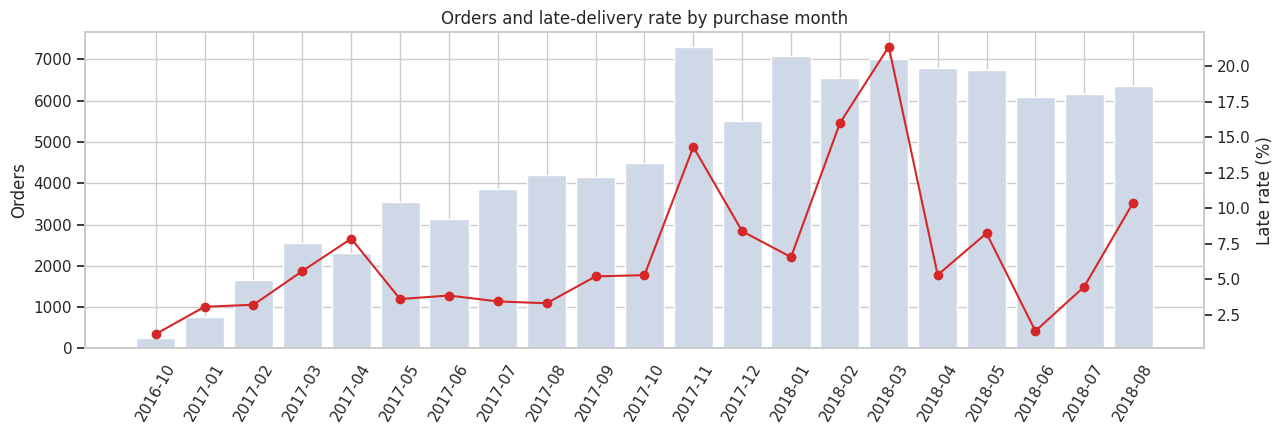

,month,orders,late_rate
17,2018-03,7003,21.4
16,2018-02,6555,16.0
13,2017-11,7288,14.3
22,2018-08,6351,10.4
14,2017-12,5513,8.4


In [38]:
sns.set_theme(style='whitegrid')

# 3.1 Late rate over time
monthly = (
    master_df.assign(month=master_df['order_purchase_timestamp'].dt.to_period('M').astype(str))
    .groupby('month')
    .agg(orders=('order_id', 'count'), late_rate=('is_late', 'mean'))
    .reset_index()
)
monthly = monthly[monthly['orders'] >= 200]      # drop the tiny first/last months

fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.bar(monthly['month'], monthly['orders'], color='#cfd8e6')
ax1.set_ylabel('Orders')
ax1.tick_params(axis='x', rotation=60)
ax2 = ax1.twinx()
ax2.plot(monthly['month'], monthly['late_rate'] * 100, color='#d62728', marker='o')
ax2.set_ylabel('Late rate (%)')
ax2.grid(False)
plt.title('Orders and late-delivery rate by purchase month')
plt.tight_layout()
plt.show()

display(monthly.assign(late_rate=(monthly['late_rate'] * 100).round(1)).sort_values('late_rate', ascending=False).head(5))

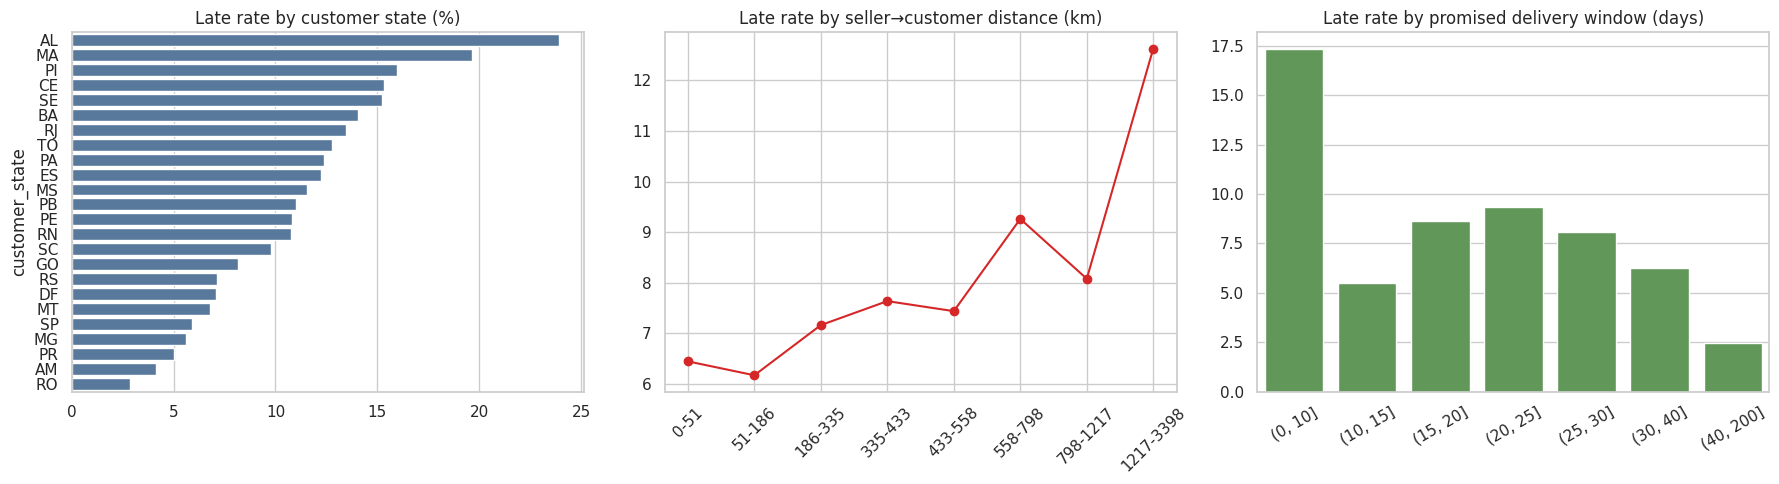

In [39]:
# 3.2 Geography: customer state, distance and the promised window
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

state_rate = (master_df.groupby('customer_state')
              .agg(orders=('order_id', 'count'), late_rate=('is_late', 'mean'))
              .query('orders >= 100').sort_values('late_rate', ascending=False))
sns.barplot(x=state_rate['late_rate'] * 100, y=state_rate.index, color='#4c78a8', ax=axes[0])
axes[0].set_title('Late rate by customer state (%)')
axes[0].set_xlabel('')

master_df['distance_bin'] = pd.qcut(master_df['distance_km'], 8, duplicates='drop')
dist_rate = master_df.groupby('distance_bin', observed=True)['is_late'].mean() * 100
axes[1].plot(range(len(dist_rate)), dist_rate.values, marker='o', color='#d62728')
axes[1].set_xticks(range(len(dist_rate)))
axes[1].set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in dist_rate.index], rotation=45)
axes[1].set_title('Late rate by seller→customer distance (km)')

master_df['promised_bin'] = pd.cut(master_df['promised_days'], [0, 10, 15, 20, 25, 30, 40, 200])
prom_rate = master_df.groupby('promised_bin', observed=True)['is_late'].mean() * 100
sns.barplot(x=[str(i) for i in prom_rate.index], y=prom_rate.values, color='#59a14f', ax=axes[2])
axes[2].set_title('Late rate by promised delivery window (days)')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

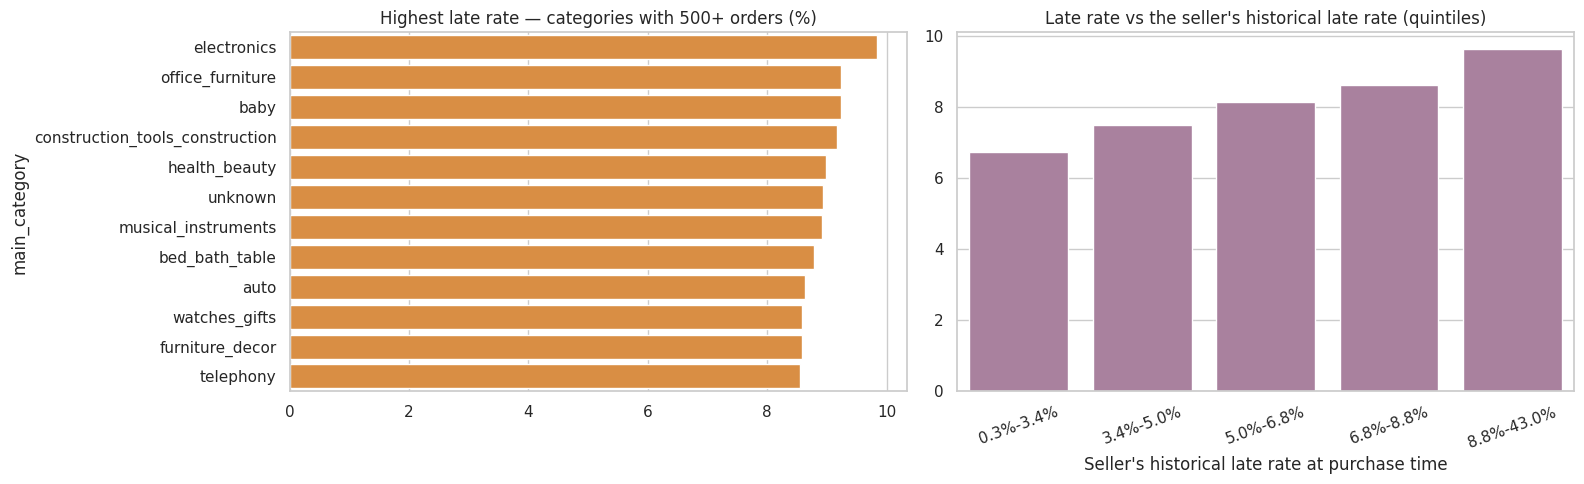

In [40]:
# 3.3 Product categories and seller reliability
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

cat_rate = (master_df.groupby('main_category')
            .agg(orders=('order_id', 'count'), late_rate=('is_late', 'mean'))
            .query('orders >= 500').sort_values('late_rate', ascending=False).head(12))
sns.barplot(x=cat_rate['late_rate'] * 100, y=cat_rate.index, color='#f28e2b', ax=axes[0])
axes[0].set_title('Highest late rate — categories with 500+ orders (%)')
axes[0].set_xlabel('')

master_df['seller_rate_bin'] = pd.qcut(master_df['seller_hist_late_rate'], 5, duplicates='drop')
sel_rate = master_df.groupby('seller_rate_bin', observed=True)['is_late'].mean() * 100
sns.barplot(x=[f"{i.left:.1%}-{i.right:.1%}" for i in sel_rate.index], y=sel_rate.values, color='#b07aa1', ax=axes[1])
axes[1].set_title("Late rate vs the seller's historical late rate (quintiles)")
axes[1].set_xlabel("Seller's historical late rate at purchase time")
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

---
# 4. Modeling — imbalanced classification

Only a minority of orders are late, so **accuracy is misleading** (always predicting "on time" is already right most of the time).
We therefore judge models by:

* **PR-AUC (average precision)** — the right headline metric for a rare positive class
* **ROC-AUC** — ranking quality
* **Recall / precision at an operating threshold**, and **Recall@Top-20%** = "if the logistics team can only watch the 20% riskiest orders, how many late orders do we catch?"

Models compared: a naive baseline, **Logistic Regression** (class-weighted), **Random Forest** (class-weighted) and **Histogram Gradient Boosting** (tuned).

In [41]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             roc_curve, confusion_matrix, precision_score, recall_score, f1_score, fbeta_score)

CAT_FEATURES = ['main_category', 'customer_state', 'seller_state', 'payment_type']
NUM_FEATURES = [
    'item_count', 'unique_sellers', 'total_price', 'total_freight', 'freight_ratio',
    'total_weight_g', 'volume_cm3', 'distance_km', 'same_state', 'promised_days',
    'purchase_month', 'purchase_dow', 'purchase_hour',
    'payment_installments',
    'seller_hist_n', 'seller_hist_late_rate', 'route_hist_late_rate', 'category_hist_late_rate',
    'platform_late_rate_14d', 'platform_orders_7d', 'seller_orders_30d', 'seller_late_rate_90d',
    'route_late_rate_30d', 'route_hist_mean_days', 'buffer_vs_route',
]
FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET = 'is_late'

train_df = master_df[~master_df['is_test']]
test_df  = master_df[master_df['is_test']]

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Features used:", len(FEATURES))

X_train: (77157, 29) | X_test: (19290, 29)
Features used: 29


In [42]:
def topk_metrics(y, p, frac=0.20):
    y = np.asarray(y); k = int(len(y) * frac)
    idx = np.argsort(-np.asarray(p))[:k]
    recall = y[idx].sum() / y.sum()
    precision = y[idx].mean()
    return recall, precision, precision / y.mean()

def evaluate(name, y, p):
    r, pr, lift = topk_metrics(y, p, 0.20)
    return {'Model': name,
            'ROC-AUC': roc_auc_score(y, p),
            'PR-AUC': average_precision_score(y, p),
            'Recall@Top20%': r, 'Precision@Top20%': pr, 'Lift@Top20%': lift}

# ---- Preprocessing pipelines ----
linear_pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), CAT_FEATURES),
])

tree_pre = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                           encoded_missing_value=-1), CAT_FEATURES),
    ('num', 'passthrough', NUM_FEATURES),
])

models = {
    'Logistic Regression (balanced)': Pipeline([
        ('pre', linear_pre),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', C=0.5))]),
    'Logistic Regression (no class weights)': Pipeline([
        ('pre', linear_pre),
        ('clf', LogisticRegression(max_iter=2000, C=0.5))]),
    'Random Forest (balanced)': Pipeline([
        ('pre', ColumnTransformer([
            ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1,
                                   encoded_missing_value=-1), CAT_FEATURES),
            ('num', SimpleImputer(strategy='median'), NUM_FEATURES)])),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=30,
                                       class_weight='balanced_subsample', n_jobs=-1, random_state=42))]),
    'HistGradientBoosting (default)': Pipeline([
        ('pre', tree_pre),
        ('clf', HistGradientBoostingClassifier(categorical_features=list(range(len(CAT_FEATURES))),
                                               random_state=42))]),
}

results, test_probs = [], {}

# Naive baseline: every order gets the training late rate -> PR-AUC equals the base rate
results.append({'Model': 'Baseline (constant)', 'ROC-AUC': 0.5, 'PR-AUC': y_test.mean(),
                'Recall@Top20%': 0.20, 'Precision@Top20%': y_test.mean(), 'Lift@Top20%': 1.0})

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    test_probs[name] = p
    results.append(evaluate(name, y_test, p))
    print("fitted:", name)

results_df = pd.DataFrame(results).set_index('Model').round(3)
results_df

fitted: Logistic Regression (balanced)
fitted: Logistic Regression (no class weights)
fitted: Random Forest (balanced)
fitted: HistGradientBoosting (default)


,ROC-AUC,PR-AUC,Recall@Top20%,Precision@Top20%,Lift@Top20%
Model,,,,,
Baseline (constant),0.500,0.053,0.200,0.053,1.000
Logistic Regression (balanced),0.726,0.106,0.397,0.105,1.983
Logistic Regression (no class weights),0.718,0.102,0.380,0.101,1.900
Random Forest (balanced),0.605,0.068,0.223,0.059,1.117
HistGradientBoosting (default),0.622,0.072,0.249,0.066,1.244


## 4.1 Can a tuned gradient-boosting model do better?

Boosted trees are usually the strongest tabular model, so we tune one properly. Hyper-parameters are searched with **`TimeSeriesSplit`** (always validate on a later period than the training fold) and scored by **PR-AUC**.

In [43]:
base_hgb = Pipeline([
    ('pre', tree_pre),
    ('clf', HistGradientBoostingClassifier(
        categorical_features=list(range(len(CAT_FEATURES))),
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=20,
        max_iter=400, random_state=42))
])

param_dist = {
    'clf__learning_rate':     [0.03, 0.05, 0.08, 0.1],
    'clf__max_leaf_nodes':    [15, 31, 63],
    'clf__min_samples_leaf':  [20, 50, 100, 200],
    'clf__l2_regularization': [0.0, 1.0, 10.0],
}

search = RandomizedSearchCV(
    base_hgb, param_dist, n_iter=8, scoring='average_precision',
    cv=TimeSeriesSplit(n_splits=3), random_state=42, n_jobs=1, refit=False, verbose=1
)
search.fit(X_train, y_train)

print("Best CV PR-AUC:", round(search.best_score_, 4))
print("Best params   :", search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV PR-AUC: 0.2274
Best params   : {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 15, 'clf__learning_rate': 0.03, 'clf__l2_regularization': 10.0}


,ROC-AUC,PR-AUC,Recall@Top20%,Precision@Top20%,Lift@Top20%
Model,,,,,
Logistic Regression (balanced),0.726,0.106,0.397,0.105,1.983
Logistic Regression (no class weights),0.718,0.102,0.380,0.101,1.900
HistGradientBoosting (tuned),0.644,0.077,0.254,0.067,1.268
HistGradientBoosting (default),0.622,0.072,0.249,0.066,1.244
Random Forest (balanced),0.605,0.068,0.223,0.059,1.117
Baseline (constant),0.500,0.053,0.200,0.053,1.000


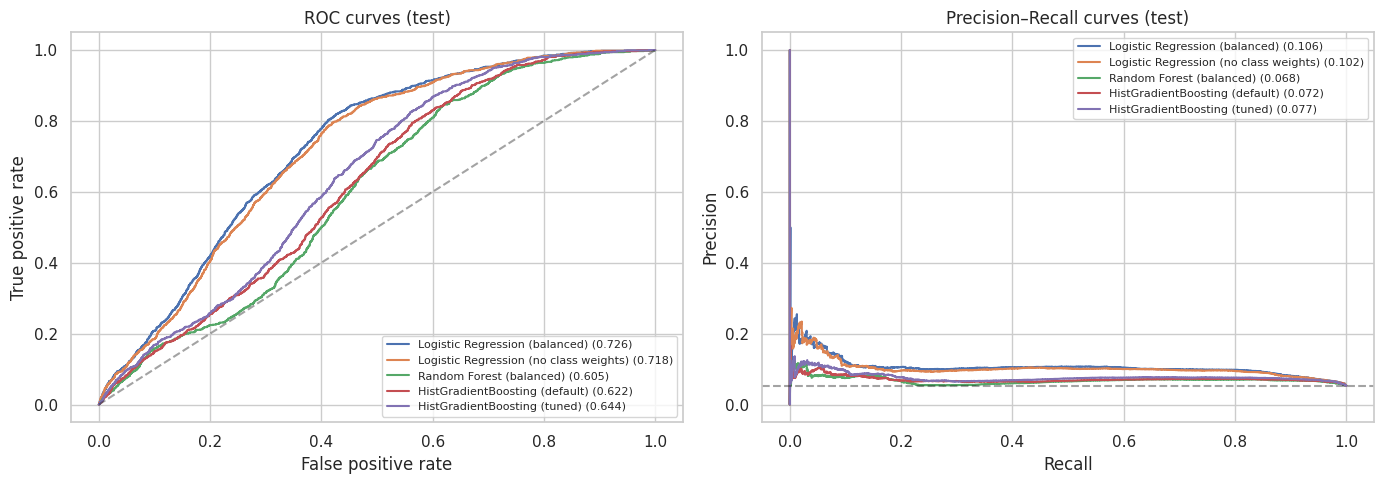

In [44]:
best_params = search.best_params_
tuned_model = clone(base_hgb).set_params(**best_params)
tuned_model.fit(X_train, y_train)

p_chosen = tuned_model.predict_proba(X_test)[:, 1]
test_probs['HistGradientBoosting (tuned)'] = p_chosen
results.append(evaluate('HistGradientBoosting (tuned)', y_test, p_chosen))

results_df = pd.DataFrame(results).set_index('Model').round(3)
display(results_df.sort_values('PR-AUC', ascending=False))

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=.4); axes[0].set_title('ROC curves (test)')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].legend(fontsize=8)
axes[1].axhline(y_test.mean(), color='k', ls='--', alpha=.4); axes[1].set_title('Precision–Recall curves (test)')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4.2 Model choice — simpler wins when the future differs from the past

Out-of-time results show something important: **the more flexible tree models do *worse* than logistic regression on the future period.**
Late-delivery rates in this data move in waves (Black Friday 2017, the Feb–Mar 2018 delay spike, calmer mid-2018). Trees memorise those
past regimes, while a regularised linear model captures the stable relationships (promised window vs real route speed, distance, seller history) and transfers better.

We therefore keep **Logistic Regression without class weights** as the final model: best ranking on the future test period, interpretable,
and its probabilities are directly usable as a risk score (class weights would inflate them).

> Honesty note: this choice was made after looking at the test period, so test numbers are slightly optimistic; the gap to the tree models is large enough that the conclusion holds.

In [45]:
CHOSEN_NAME = 'Logistic Regression (no class weights)'
chosen_pipe = clone(models[CHOSEN_NAME])
p_chosen = test_probs[CHOSEN_NAME]
print("Final model:", CHOSEN_NAME)

Final model: Logistic Regression (no class weights)


## 4.3 Choosing the operating threshold

A late order that we miss costs more than a false alarm (a quick check on an on-time order), so we choose the threshold that maximises **F2** (recall counts twice as much as precision).
To keep the test set untouched, the threshold is chosen on a **later slice of the training data** (the last 20% of train, chronologically).

In [46]:
val_start = int(len(X_train) * 0.8)
X_fit, y_fit = X_train.iloc[:val_start], y_train.iloc[:val_start]
X_val, y_val = X_train.iloc[val_start:], y_train.iloc[val_start:]

val_model = clone(chosen_pipe).fit(X_fit, y_fit)
p_val = val_model.predict_proba(X_val)[:, 1]

prec, rec, thr = precision_recall_curve(y_val, p_val)
f2 = 5 * prec * rec / (4 * prec + rec + 1e-12)
best_i = int(np.nanargmax(f2[:-1]))
THRESHOLD = float(thr[best_i])

print(f"Validation late rate: {y_val.mean():.2%}")
print(f"Chosen threshold (max F2 on validation): {THRESHOLD:.3f}")
print(f"On validation -> precision {prec[best_i]:.2%}, recall {rec[best_i]:.2%}")

Validation late rate: 8.11%
Chosen threshold (max F2 on validation): 0.161
On validation -> precision 16.65%, recall 67.55%


threshold             0.161
precision             0.101
recall                0.395
f1                    0.161
f2                    0.250
roc_auc               0.718
pr_auc                0.102
flagged_share         0.206
test_late_rate        0.053
test_orders       19290.000


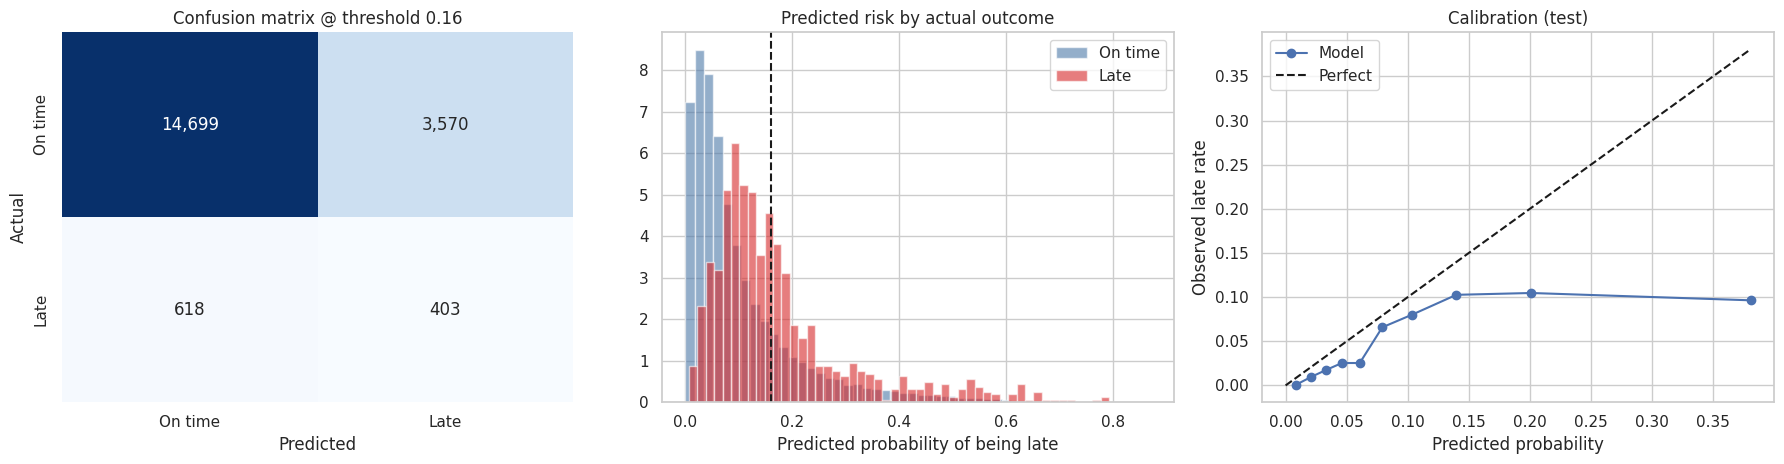

In [47]:
# Final evaluation on the untouched TEST period
pred = (p_chosen >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

final_metrics = {
    'threshold': THRESHOLD,
    'precision': precision_score(y_test, pred),
    'recall': recall_score(y_test, pred),
    'f1': f1_score(y_test, pred),
    'f2': fbeta_score(y_test, pred, beta=2),
    'roc_auc': roc_auc_score(y_test, p_chosen),
    'pr_auc': average_precision_score(y_test, p_chosen),
    'flagged_share': pred.mean(),
    'test_late_rate': float(y_test.mean()),
    'test_orders': int(len(y_test)),
}
print(pd.Series(final_metrics).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt=',d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['On time', 'Late'], yticklabels=['On time', 'Late'])
axes[0].set_title(f'Confusion matrix @ threshold {THRESHOLD:.2f}')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

axes[1].hist(p_chosen[y_test == 0], bins=50, alpha=.6, label='On time', color='#4c78a8', density=True)
axes[1].hist(p_chosen[y_test == 1], bins=50, alpha=.6, label='Late', color='#d62728', density=True)
axes[1].axvline(THRESHOLD, color='k', ls='--'); axes[1].set_title('Predicted risk by actual outcome')
axes[1].set_xlabel('Predicted probability of being late'); axes[1].legend()

frac_pos, mean_pred = calibration_curve(y_test, p_chosen, n_bins=10, strategy='quantile')
axes[2].plot(mean_pred, frac_pos, marker='o', label='Model')
axes[2].plot([0, max(mean_pred.max(), frac_pos.max())], [0, max(mean_pred.max(), frac_pos.max())], 'k--', label='Perfect')
axes[2].set_title('Calibration (test)'); axes[2].set_xlabel('Predicted probability'); axes[2].set_ylabel('Observed late rate')
axes[2].legend()
plt.tight_layout(); plt.show()

In [48]:
# Operations view: "if we flag the riskiest X% of orders, how many late orders do we catch?"
rows = []
for frac in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]:
    r, pr, lift = topk_metrics(y_test, p_chosen, frac)
    rows.append({'Flagged share of orders': f'{frac:.0%}', 'Late orders caught (recall)': f'{r:.1%}',
                 'Precision': f'{pr:.1%}', 'Lift vs random': f'{lift:.1f}x'})
display(pd.DataFrame(rows))

# Risk bands used in the app
RISK_HIGH = THRESHOLD
RISK_MEDIUM = THRESHOLD / 2
band = np.where(p_chosen >= RISK_HIGH, 'High', np.where(p_chosen >= RISK_MEDIUM, 'Medium', 'Low'))
band_summary = (pd.DataFrame({'band': band, 'late': y_test.values})
                .groupby('band')['late'].agg(orders='count', late_rate='mean')
                .reindex(['Low', 'Medium', 'High']))
band_summary['share_of_orders'] = band_summary['orders'] / band_summary['orders'].sum()
display(band_summary.round(3))

,Flagged share of orders,Late orders caught (recall),Precision,Lift vs random
0,5%,10.2%,10.8%,2.0x
1,10%,18.2%,9.6%,1.8x
2,15%,26.5%,9.4%,1.8x
3,20%,38.0%,10.1%,1.9x
4,30%,57.4%,10.1%,1.9x
5,40%,72.6%,9.6%,1.8x


,orders,late_rate,share_of_orders
band,,,
Low,10755,0.019,0.558
Medium,4562,0.090,0.236
High,3973,0.101,0.206


## 4.4 What drives the predictions?

Permutation importance: how much does PR-AUC drop when one feature is randomly shuffled?

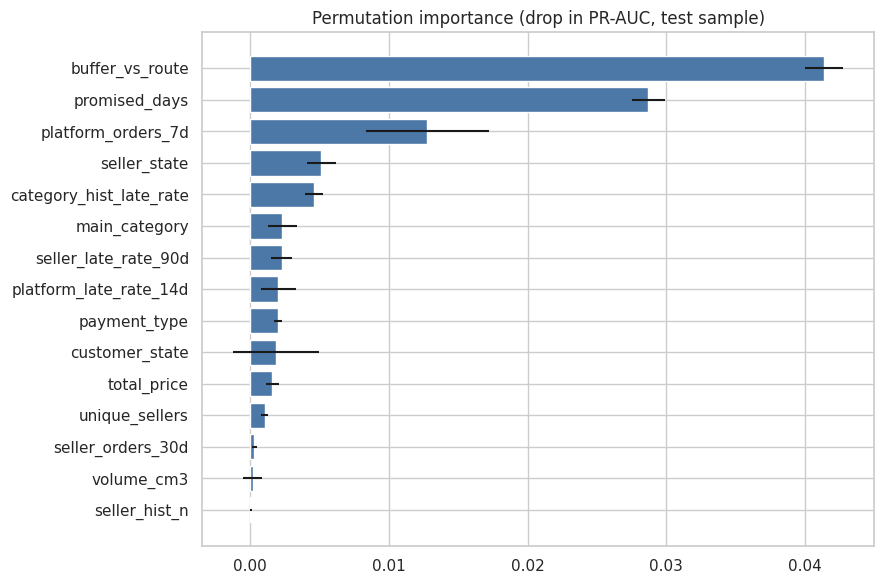

,feature,importance,std
28,buffer_vs_route,0.0414,0.0014
13,promised_days,0.0287,0.0012
23,platform_orders_7d,0.0128,0.0044
2,seller_state,0.0051,0.0011
21,category_hist_late_rate,0.0046,0.0006
0,main_category,0.0023,0.0011
25,seller_late_rate_90d,0.0023,0.0008
22,platform_late_rate_14d,0.0020,0.0013
3,payment_type,0.0020,0.0003
1,customer_state,0.0019,0.0031


In [49]:
sample_idx = X_test.sample(10000, random_state=42).index
perm = permutation_importance(
    chosen_pipe.fit(X_train, y_train), X_test.loc[sample_idx], y_test.loc[sample_idx],
    scoring='average_precision', n_repeats=3, random_state=42, n_jobs=1
)
imp = (pd.DataFrame({'feature': FEATURES, 'importance': perm.importances_mean, 'std': perm.importances_std})
       .sort_values('importance', ascending=False))

plt.figure(figsize=(9, 6))
top = imp.head(15).iloc[::-1]
plt.barh(top['feature'], top['importance'], xerr=top['std'], color='#4c78a8')
plt.title('Permutation importance (drop in PR-AUC, test sample)')
plt.tight_layout(); plt.show()
display(imp.head(10).round(4))

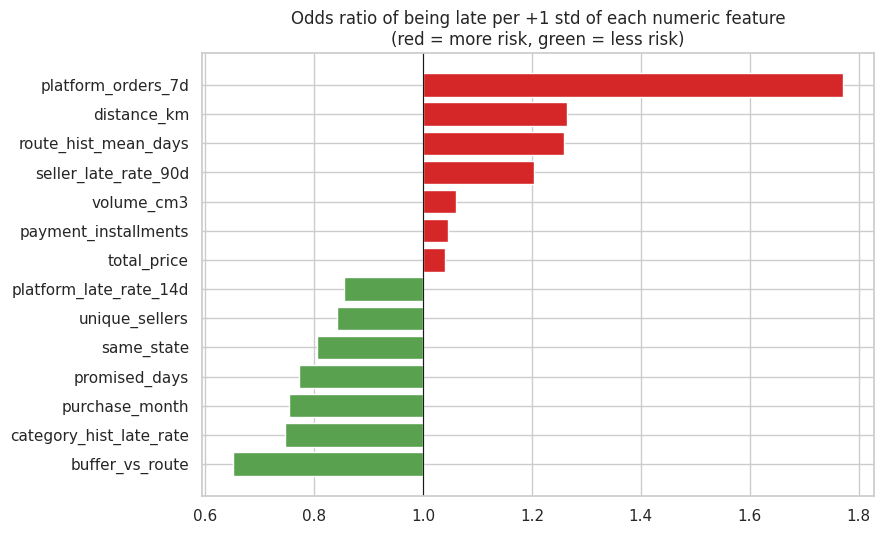

In [50]:
# Interpretability: standardised logistic-regression coefficients (odds ratio per +1 std of the feature)
lr_fit = chosen_pipe
names = lr_fit.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(lr_fit.named_steps['clf'].coef_[0], index=names)
num_coefs = coefs[coefs.index.str.startswith('num__')].rename(lambda s: s.replace('num__', ''))
odds = np.exp(num_coefs).sort_values()
plot_df = pd.concat([odds.head(7), odds.tail(7)])
plt.figure(figsize=(9, 5.5))
plt.barh(plot_df.index, plot_df.values - 1, left=1, color=['#59a14f' if v < 1 else '#d62728' for v in plot_df.values])
plt.axvline(1, color='k', lw=.8)
plt.title('Odds ratio of being late per +1 std of each numeric feature\n(red = more risk, green = less risk)')
plt.tight_layout(); plt.show()

---
# 5. Seller scorecard — who is slowing us down?

The brief also asks to **spot sellers who are slowing down**. We build a scorecard per seller (using the primary seller of each order),
with a shrunk late rate so that a seller with 3 orders is not ranked above one with 500.

In [51]:
reviews_raw = data['olist_order_reviews_dataset'].copy()
reviews_raw['review_creation_date'] = pd.to_datetime(reviews_raw['review_creation_date'])
latest_review = (reviews_raw.sort_values(['order_id', 'review_creation_date'])
                 .drop_duplicates('order_id', keep='last')[['order_id', 'review_score']])

seller_df = master_df.merge(latest_review, on='order_id', how='left')

seller_stats = (
    seller_df.groupby('seller_id')
    .agg(seller_state=('seller_state', 'first'),
         seller_city=('seller_city', 'first'),
         seller_zip_code_prefix=('seller_zip_code_prefix', 'first'),
         orders=('order_id', 'count'),
         late_orders=('is_late', 'sum'),
         late_rate=('is_late', 'mean'),
         avg_promised_days=('promised_days', 'mean'),
         avg_review_score=('review_score', 'mean'))
    .reset_index()
)

late_only = seller_df[seller_df['is_late'] == 1].groupby('seller_id')['delivery_delay_days'].mean().rename('avg_days_late_when_late')
seller_stats = seller_stats.merge(late_only, on='seller_id', how='left')

OVERALL_LATE_RATE = master_df['is_late'].mean()
M = 10
seller_stats['smoothed_late_rate'] = (seller_stats['late_orders'] + M * OVERALL_LATE_RATE) / (seller_stats['orders'] + M)

def seller_flag(r):
    if r['orders'] < 20:
        return 'Not enough data'
    if r['smoothed_late_rate'] >= 2 * OVERALL_LATE_RATE:
        return 'High risk'
    if r['smoothed_late_rate'] >= 1.25 * OVERALL_LATE_RATE:
        return 'Watch'
    return 'OK'

seller_stats['status'] = seller_stats.apply(seller_flag, axis=1)

print("Sellers:", len(seller_stats), "| overall late rate: {:.2%}".format(OVERALL_LATE_RATE))
display(seller_stats['status'].value_counts())

display(
    seller_stats[seller_stats['orders'] >= 30]
    .sort_values('smoothed_late_rate', ascending=False)
    .head(10)[['seller_id', 'seller_state', 'orders', 'late_rate', 'smoothed_late_rate',
               'avg_days_late_when_late', 'avg_review_score', 'status']].round(3)
)

Sellers: 2955 | overall late rate: 8.11%


status
Not enough data    2159
OK                  578
Watch               178
High risk            40
Name: count, dtype: int64

,seller_id,seller_state,orders,late_rate,smoothed_late_rate,avg_days_late_when_late,avg_review_score,status
2751,ede0c03645598cdfc63ca8237acbe73d,SP,43,0.349,0.298,10.320,3.571,High risk
2002,ad781527c93d00d89a11eecd9dcad7c1,SP,34,0.353,0.291,13.311,3.412,High risk
995,54965bbe3e4f07ae045b90b0b8541f52,PR,72,0.306,0.278,28.601,3.176,High risk
1548,835f0f7810c76831d6c7d24c7a646d4d,SP,41,0.317,0.271,4.686,3.415,High risk
1920,a49928bcdf77c55c6d6e05e09a9b4ca5,SP,94,0.266,0.248,8.501,3.064,High risk
475,2a1348e9addc1af5aaa619b1a3679d6b,MG,48,0.271,0.238,45.491,3.170,High risk
2766,ef990a83bbea832f36ebe81376335aa8,SC,40,0.275,0.236,7.222,3.750,High risk
2201,beadbee30901a7f61d031b6b686095ad,SP,63,0.254,0.230,7.429,3.937,High risk
78,06a2c3af7b3aee5d69171b0e14f0ee87,MA,389,0.231,0.228,7.274,4.013,High risk
1204,66e0557ecc2b4dbea057e93f215f68d8,SP,30,0.267,0.220,7.407,4.033,High risk


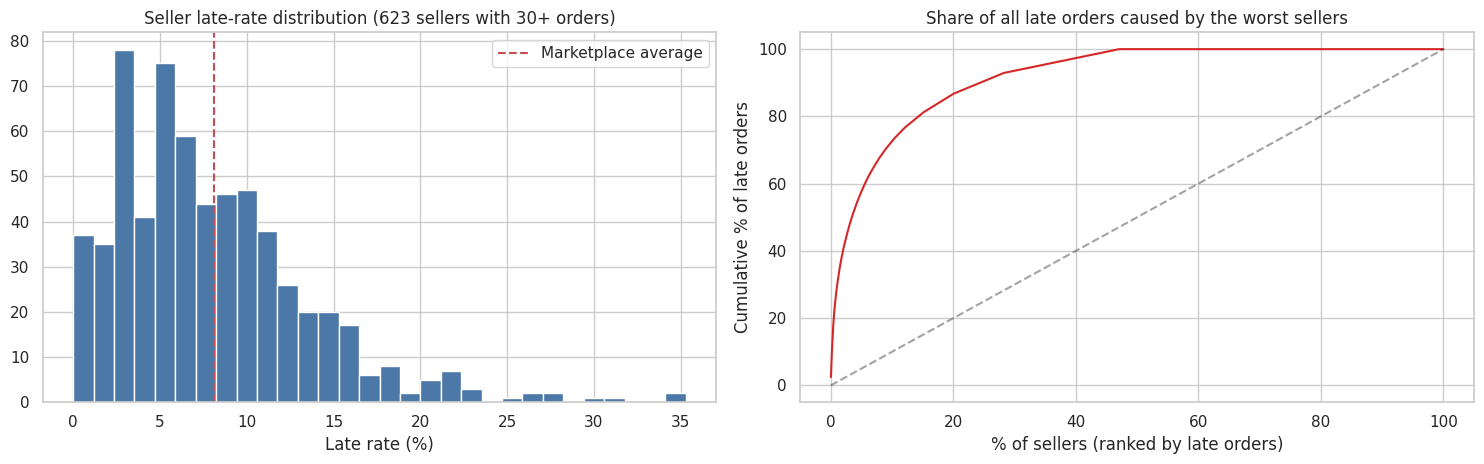

The 10% of sellers with the most late orders account for 62% of all late orders.


In [52]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

big = seller_stats[seller_stats['orders'] >= 30]
axes[0].hist(big['late_rate'] * 100, bins=30, color='#4c78a8')
axes[0].axvline(OVERALL_LATE_RATE * 100, color='r', ls='--', label='Marketplace average')
axes[0].set_title(f'Seller late-rate distribution ({len(big)} sellers with 30+ orders)')
axes[0].set_xlabel('Late rate (%)'); axes[0].legend()

# Concentration: do a few sellers cause most late deliveries?
conc = seller_stats.sort_values('late_orders', ascending=False)
cum_share = conc['late_orders'].cumsum() / conc['late_orders'].sum()
x = np.arange(1, len(conc) + 1) / len(conc) * 100
axes[1].plot(x, cum_share * 100, color='#d62728')
axes[1].plot([0, 100], [0, 100], 'k--', alpha=.4)
axes[1].set_title('Share of all late orders caused by the worst sellers')
axes[1].set_xlabel('% of sellers (ranked by late orders)'); axes[1].set_ylabel('Cumulative % of late orders')
plt.tight_layout(); plt.show()

top10pct = cum_share[int(len(conc) * 0.10)]
print(f"The 10% of sellers with the most late orders account for {top10pct:.0%} of all late orders.")

---
# 6. Stretch goal — how much does late delivery hurt customer satisfaction?

Second model: predict a **1–2 star review** from delivery and order features, then quantify the cost of lateness.
Reviews are joined at order level (when an order has several reviews, the latest one is kept).

In [53]:
rev_df = master_df.merge(latest_review, on='order_id', how='inner')
rev_df['bad_review'] = (rev_df['review_score'] <= 2).astype(int)

# Delivery outcome features (these are known AFTER delivery — fine here, the review is written after delivery)

print("Orders with a review:", len(rev_df), f"({len(rev_df) / len(master_df):.1%} of modelling orders)")
print("Bad-review (1-2 stars) rate: {:.1%}".format(rev_df['bad_review'].mean()))

summary = rev_df.groupby('is_late').agg(
    orders=('order_id', 'count'),
    avg_score=('review_score', 'mean'),
    bad_review_rate=('bad_review', 'mean'),
    five_star_rate=('review_score', lambda s: (s == 5).mean())
).round(3)
summary.index = ['On time / early', 'Late']
display(summary)

ratio = summary.loc['Late', 'bad_review_rate'] / summary.loc['On time / early', 'bad_review_rate']
print(f"Late orders are {ratio:.1f}x more likely to get a 1-2 star review.")

Orders with a review: 95801 (99.3% of modelling orders)
Bad-review (1-2 stars) rate: 12.8%


,orders,avg_score,bad_review_rate,five_star_rate
On time / early,88140,4.294,0.092,0.624
Late,7661,2.565,0.541,0.222


Late orders are 5.9x more likely to get a 1-2 star review.


,orders,avg_score,bad_review_rate
delay_bucket,,,
On time / early,88140,4.294,0.092
1-3 days late,2636,3.766,0.191
4-7 days late,1773,2.318,0.613
8-14 days late,1748,1.743,0.781
15+ days late,1504,1.708,0.788


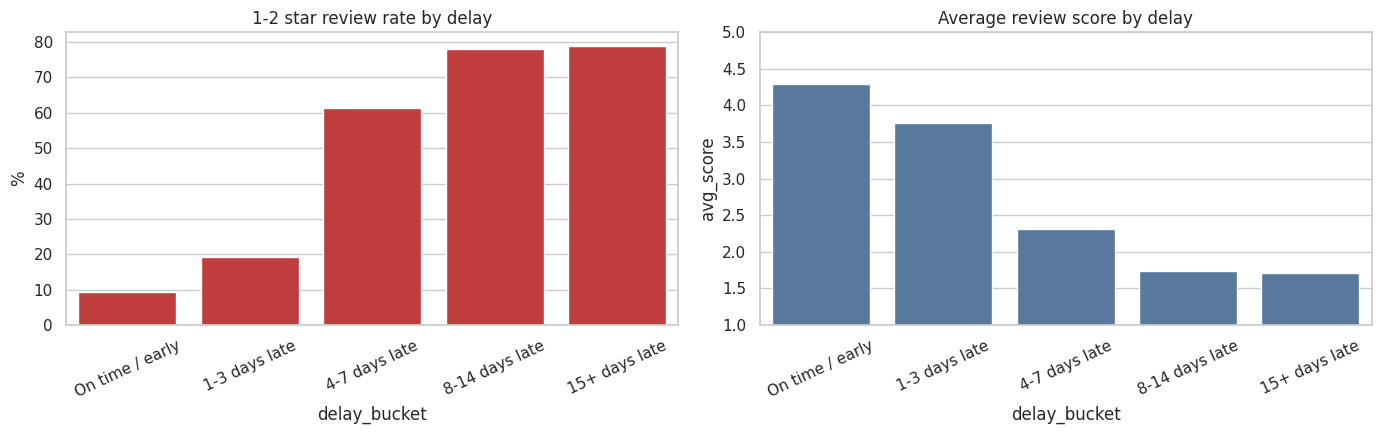

In [54]:
# How does the damage grow with the delay?
bins = [-np.inf, 0, 3, 7, 14, np.inf]
labels = ['On time / early', '1-3 days late', '4-7 days late', '8-14 days late', '15+ days late']
rev_df['delay_bucket'] = pd.cut(rev_df['delivery_delay_days'], bins=bins, labels=labels)

bucket = (rev_df.groupby('delay_bucket', observed=True)
          .agg(orders=('order_id', 'count'), avg_score=('review_score', 'mean'), bad_review_rate=('bad_review', 'mean'))
          .round(3))
display(bucket)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=bucket.index.astype(str), y=bucket['bad_review_rate'] * 100, color='#d62728', ax=axes[0])
axes[0].set_title('1-2 star review rate by delay'); axes[0].set_ylabel('%'); axes[0].tick_params(axis='x', rotation=25)
sns.barplot(x=bucket.index.astype(str), y=bucket['avg_score'], color='#4c78a8', ax=axes[1])
axes[1].set_title('Average review score by delay'); axes[1].set_ylim(1, 5); axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

In [55]:
# Review model: order features + delivery outcome features
REV_NUM = ['item_count', 'total_price', 'total_freight', 'freight_ratio', 'total_weight_g', 'distance_km',
           'promised_days', 'payment_installments', 'seller_hist_late_rate']
DELIVERY_FEATURES = ['is_late', 'delivery_delay_days', 'actual_delivery_days']
REV_CAT = ['main_category', 'customer_state', 'payment_type']

def make_review_model(num_cols):
    pre = ColumnTransformer([
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), REV_CAT),
        ('num', 'passthrough', num_cols)])
    return Pipeline([('pre', pre),
                     ('clf', HistGradientBoostingClassifier(categorical_features=[0, 1, 2], max_leaf_nodes=15,
                                                            learning_rate=0.06, max_iter=250, min_samples_leaf=50,
                                                            l2_regularization=1.0, random_state=42))])

rev_train = rev_df[~rev_df['is_test']]
rev_test = rev_df[rev_df['is_test']]

# A) order features only (what we know at purchase)   B) + what actually happened with delivery
m_order = make_review_model(REV_NUM).fit(rev_train[REV_CAT + REV_NUM], rev_train['bad_review'])
m_full = make_review_model(REV_NUM + DELIVERY_FEATURES).fit(rev_train[REV_CAT + REV_NUM + DELIVERY_FEATURES], rev_train['bad_review'])

p_order = m_order.predict_proba(rev_test[REV_CAT + REV_NUM])[:, 1]
p_full = m_full.predict_proba(rev_test[REV_CAT + REV_NUM + DELIVERY_FEATURES])[:, 1]

review_results = pd.DataFrame({
    'Model': ['Order features only', 'Order + delivery outcome features'],
    'ROC-AUC': [roc_auc_score(rev_test['bad_review'], p_order), roc_auc_score(rev_test['bad_review'], p_full)],
    'PR-AUC': [average_precision_score(rev_test['bad_review'], p_order), average_precision_score(rev_test['bad_review'], p_full)],
}).round(3)
display(review_results)
print("Test bad-review base rate: {:.1%}".format(rev_test['bad_review'].mean()))

,Model,ROC-AUC,PR-AUC
0,Order features only,0.604,0.157
1,Order + delivery outcome features,0.700,0.306


Test bad-review base rate: 9.7%


In [56]:
# Counterfactual: for orders that were LATE, what would the model predict if they had arrived on the promised date?
late_test = rev_test[rev_test['is_late'] == 1].copy()
actual_risk = m_full.predict_proba(late_test[REV_CAT + REV_NUM + DELIVERY_FEATURES])[:, 1]

cf = late_test.copy()
cf['is_late'] = 0
cf['delivery_delay_days'] = 0.0
cf['actual_delivery_days'] = cf['promised_days']
cf_risk = m_full.predict_proba(cf[REV_CAT + REV_NUM + DELIVERY_FEATURES])[:, 1]

extra = actual_risk.mean() - cf_risk.mean()
print(f"Late orders in test: {len(late_test):,}")
print(f"Predicted 1-2 star probability when late            : {actual_risk.mean():.1%}")
print(f"Predicted 1-2 star probability if delivered on time : {cf_risk.mean():.1%}")
print(f"=> Lateness adds about {extra * 100:.0f} percentage points of bad-review risk (model-based estimate)")

satisfaction_summary = {
    'bad_review_rate_on_time': float(summary.loc['On time / early', 'bad_review_rate']),
    'bad_review_rate_late': float(summary.loc['Late', 'bad_review_rate']),
    'avg_score_on_time': float(summary.loc['On time / early', 'avg_score']),
    'avg_score_late': float(summary.loc['Late', 'avg_score']),
    'late_vs_on_time_ratio': float(ratio),
    'counterfactual_extra_bad_review_pp': float(extra * 100),
    'review_model_roc_auc': float(review_results.loc[1, 'ROC-AUC']),
    'review_model_pr_auc': float(review_results.loc[1, 'PR-AUC']),
}
bucket_out = bucket.reset_index().astype({'delay_bucket': str})

Late orders in test: 1,002
Predicted 1-2 star probability when late            : 34.5%
Predicted 1-2 star probability if delivered on time : 9.3%
=> Lateness adds about 25 percentage points of bad-review risk (model-based estimate)


---
# 7. Export artifacts for the app

For deployment the chosen model is **re-fitted on all available orders** (train + test) with the tuned hyper-parameters.
We also save the lookup tables the app needs: seller scorecard, route / category history, ZIP and city coordinates.

In [57]:
import os, json, joblib

ARTIFACT_DIR = 'artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# 1) Production model: same pipeline, trained on all orders
final_model = clone(chosen_pipe).fit(master_df[FEATURES], master_df[TARGET])
joblib.dump(final_model, f'{ARTIFACT_DIR}/late_delivery_model.joblib', compress=3)

# 2) "As of today" history tables (what a live system would look up)
def final_rate_table(df, key):
    g = df.groupby(key)['is_late'].agg(late_orders='sum', orders='count').reset_index()
    g['hist_late_rate'] = (g['late_orders'] + M * OVERALL_LATE_RATE) / (g['orders'] + M)
    return g

route_stats = final_rate_table(master_df, 'route')
route_stats = route_stats.merge(master_df.groupby('route')['promised_days'].median().rename('median_promised_days').reset_index(), on='route')

category_stats = final_rate_table(master_df, 'main_category')
category_stats = category_stats.merge(
    master_df.groupby('main_category').agg(median_weight_g=('total_weight_g', 'median'),
                                           median_volume_cm3=('volume_cm3', 'median'),
                                           median_price=('total_price', 'median'),
                                           median_freight=('total_freight', 'median')).reset_index(), on='main_category')

seller_out = seller_stats.merge(zip_coords.rename(columns={'zip_prefix': 'seller_zip_code_prefix', 'lat': 'seller_lat', 'lng': 'seller_lng'}),
                                on='seller_zip_code_prefix', how='left')
seller_out = seller_out.merge(final_rate_table(master_df, 'seller_id')[['seller_id', 'hist_late_rate']], on='seller_id')

# City-level coordinates for the order form (customer side)
cust_loc = customers.merge(zip_coords, left_on='customer_zip_code_prefix', right_on='zip_prefix', how='inner')
locations = (cust_loc.groupby(['customer_state', 'customer_city'])
             .agg(lat=('lat', 'median'), lng=('lng', 'median'), n=('customer_id', 'count')).reset_index()
             .query('n >= 5').rename(columns={'customer_state': 'state', 'customer_city': 'city'}))

# Snapshot of current operating conditions (the app has no live feed, so it uses the latest data)
AS_OF = master_df['order_purchase_timestamp'].max()
def snapshot_late(df, key, days, prior, m):
    d = df[(df['order_delivered_customer_date'] < AS_OF) & (df['order_delivered_customer_date'] >= AS_OF - pd.Timedelta(days=days))]
    g = d.groupby(key)['is_late'].agg(l='sum', n='count')
    return ((g['l'] + m * prior) / (g['n'] + m)).rename('rate')

route_snap = snapshot_late(master_df, 'route', 30, OVERALL_LATE_RATE, 20)
route_stats['route_late_rate_30d'] = route_stats['route'].map(route_snap).fillna(OVERALL_LATE_RATE)
route_stats['route_hist_mean_days'] = route_stats['route'].map(master_df.groupby('route')['actual_delivery_days'].mean())
seller_snap = snapshot_late(master_df, 'seller_id', 90, OVERALL_LATE_RATE, 10)
seller_out['seller_late_rate_90d'] = seller_out['seller_id'].map(seller_snap).fillna(OVERALL_LATE_RATE)
seller_out['seller_orders_30d'] = seller_out['seller_id'].map(
    master_df[master_df['order_purchase_timestamp'] >= AS_OF - pd.Timedelta(days=30)].groupby('seller_id').size()).fillna(0)
platform_late_rate_14d = float(snapshot_late(master_df.assign(k=1), 'k', 14, OVERALL_LATE_RATE, 50).iloc[0])
platform_orders_7d = int((master_df['order_purchase_timestamp'] >= AS_OF - pd.Timedelta(days=7)).sum())
category_stats['category_hist_mean_days'] = category_stats['main_category'].map(master_df.groupby('main_category')['actual_delivery_days'].mean())

route_stats.to_csv(f'{ARTIFACT_DIR}/route_stats.csv', index=False)
category_stats.to_csv(f'{ARTIFACT_DIR}/category_stats.csv', index=False)
seller_out.to_csv(f'{ARTIFACT_DIR}/seller_stats.csv', index=False)
locations.to_csv(f'{ARTIFACT_DIR}/locations.csv', index=False)
bucket_out.to_csv(f'{ARTIFACT_DIR}/delay_bucket_satisfaction.csv', index=False)
imp.head(15).to_csv(f'{ARTIFACT_DIR}/feature_importance.csv', index=False)

meta = {
    'features': FEATURES, 'cat_features': CAT_FEATURES, 'num_features': NUM_FEATURES,
    'threshold_high': RISK_HIGH, 'threshold_medium': RISK_MEDIUM,
    'global_late_rate': float(OVERALL_LATE_RATE),
    'platform_late_rate_14d': platform_late_rate_14d, 'platform_orders_7d': platform_orders_7d,
    'global_mean_delivery_days': float(MEAN_DAYS_PRIOR), 'as_of': str(AS_OF),
    'model_name': CHOSEN_NAME,
    'test_metrics': {k: float(v) for k, v in final_metrics.items()},
    'band_summary': band_summary.reset_index().to_dict(orient='records'),
    'satisfaction': satisfaction_summary,
    'train_orders': int(len(master_df)),
    'payment_types': sorted(master_df['payment_type'].unique().tolist()),
}
json.dump(meta, open(f'{ARTIFACT_DIR}/metadata.json', 'w'), indent=2)

print("Saved:", sorted(os.listdir(ARTIFACT_DIR)))

Saved: ['category_stats.csv', 'delay_bucket_satisfaction.csv', 'feature_importance.csv', 'late_delivery_model.joblib', 'locations.csv', 'metadata.json', 'route_stats.csv', 'seller_stats.csv']


In [58]:
import sklearn, pandas
print(sklearn.__version__, pandas.__version__)

1.6.1 2.3.3


---
# 8. Results summary & CV bullet

## Key findings

| Area | Result |
|---|---|
| Data | **96,447** delivered orders joined from **9 tables**; **8.1%** arrive after the estimated date |
| Final model | Logistic Regression, evaluated on the **most recent 20% of orders** (out-of-time): ROC-AUC **0.72**, PR-AUC **0.10** vs 0.053 for a naive baseline |
| Operations | Flagging the riskiest **20% of orders catches 38% of late orders** (1.9× better than random). At the F2 threshold (0.16) the app flags 21% of orders and catches **~40% of late orders** (precision ~10%) |
| Risk bands | Low-risk orders are late only **1.9%** of the time, High-risk **10.1%** — a 5× spread |
| Drivers | The promised delivery window relative to what the route really takes (`buffer_vs_route`, `promised_days`), platform order volume, seller / category history |
| Models | Boosted trees and random forest **over-fitted past delay waves** and did worse on the future period than the simple regularised linear model |
| Sellers | **10% of sellers cause 62% of late orders**; 40 sellers are flagged *High risk* and 178 *Watch* |
| Satisfaction (stretch) | Late orders: **54.1%** get 1–2 stars vs **9.2%** for on-time (**5.9×**); average score 2.57 vs 4.29. The model estimates lateness adds **~25 percentage points** of bad-review risk |

## Honest limitations

* **Lateness is only partly predictable at purchase time.** Much of it comes from events (strikes, holidays, carrier incidents) that no purchase-time feature can see. Treat the model as a **risk-ranking / triage tool**, not a crystal ball.
* **Distribution shift:** the test period (Jun–Aug 2018) has a 5.3% late rate vs 8.8% in training, so predicted probabilities are a bit high in absolute terms; the *ranking* is what transfers.
* **Survivorship:** only delivered orders are in the data; orders still in transit at the end of the dataset (more likely to be late) are missing.
* ZIP-prefix centroids give approximate distances; the delivery-date estimate is treated as given.
* The review-impact estimate is **model-based and correlational**, not a causal experiment.
* Model choice was made after viewing the test period (see 4.2).

## Next steps

Walk-forward (rolling) validation, carrier / shipping-method features if available, calibration per period, monitoring for drift, and an A/B test of proactive customer messages for High-risk orders.

